# Connect to Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/drive/MyDrive/deepLearning6ModelExperiment_Assignment/Experiment_Run
%cd /content/drive/MyDrive/deepLearning6ModelExperiment_Assignment/Experiment_Run

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/deepLearning6ModelExperiment_Assignment/Results


In [ ]:
!unzip -o project_code.zip
%ls

Archive:  project_code.zip
  inflating: assemble_figures.py     
  inflating: data.py                 
  inflating: diffusion.py            
  inflating: gan_analysis.py         
  inflating: make_fig5.py            
  inflating: metrics.py              
  inflating: mlp_analysis.py         
  inflating: models.py               
  inflating: plot_sparse_features.py  
  inflating: run_dcgan.py            
  inflating: run_ddpm.py             
  inflating: run_evaluation.py       
  inflating: run_interpolation.py    
  inflating: run_mlp_experiment.py   
  inflating: run_sparse_ae.py        
  inflating: run_vae.py              
  inflating: run_vanilla_ae.py       
  inflating: run_vanilla_gan.py      
  inflating: train.py                
  inflating: README.md               
  inflating: requirements.txt        
  inflating: .gitignore              
assemble_figures.py  mlp_analysis.py          run_ddpm.py
checkpoints/         models.py                run_evaluation.py
data/         

# Requirement

In [ ]:
import random
import json
import os
import time
import copy
import math
import csv
import statistics

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import ConcatDataset, DataLoader, random_split, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid

!pip install -q torchmetrics torch-fidelity
from torchmetrics.image.fid import FrechetInceptionDistance

# Step 1: Data Preparation


Dataset: Fashion-MNIST

Device: cpu
Train / Val / Test sizes: 56000 7000 7000
Batch shape: (128, 1, 28, 28) | labels shape: (128,)
Pixel range: min=0.00, max=1.00
Test-set class counts: [700, 659, 708, 714, 707, 660, 685, 706, 738, 723]


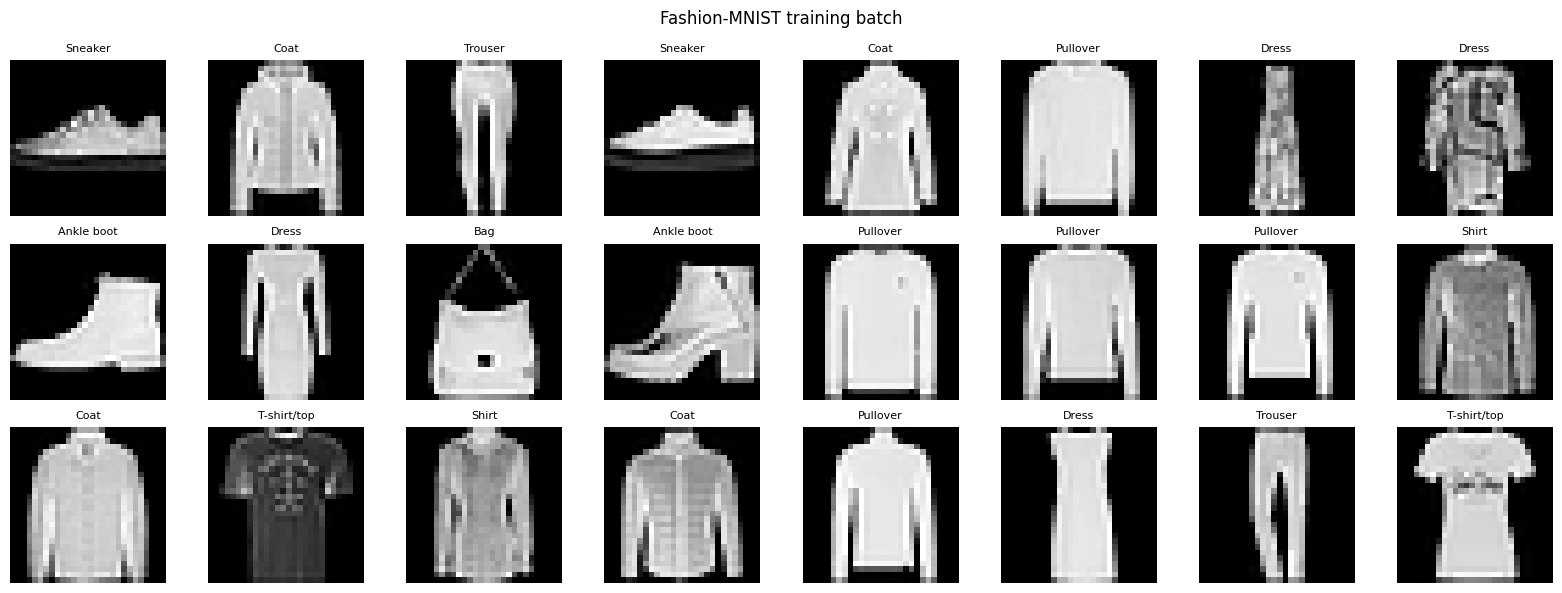

In [ ]:
SEED = 42

CLASS_NAMES = [
  "T-shirt/top",
  "Trouser",
  "Pullover",
  "Dress",
  "Coat",
  "Sandal",
  "Shirt",
  "Sneaker",
  "Bag",
  "Ankle boot",
]

# 1. Seed - Fix every random number generator we use so runs are reproducible.

def set_seed(seed: int = SEED) -> None:
  random.seed(seed)                 # Python's own RNG
  np.random.seed(seed)              # NumPy (required by the guide)
  torch.manual_seed(seed)           # PyTorch CPU (required by the guide)
  torch.cuda.manual_seed_all(seed)  # PyTorch GPU (harmless if no GPU)


# 2. Device - Use the GPU if Colab uses one, otherwise fall back to CPU.

def get_device() -> torch.device:
  return torch.device("cuda" if torch.cuda.is_available() else "cpu")


# 3. Data load + split

def get_dataloaders(batch_size: int = 128, root: str = "./data", seed: int = SEED, num_workers: int = 2):
  tfm = transforms.ToTensor()  # converts image (0-255) -> float tensor (0-1), shape [1, 28, 28]

  train_part = datasets.FashionMNIST(root, train=True, download=True, transform=tfm)
  test_part = datasets.FashionMNIST(root, train=False, download=True, transform=tfm)
  full = ConcatDataset([train_part, test_part])  # 70,000 images

  n_total = len(full) # 100%
  n_train = int(0.8 * n_total)  # 80%
  n_val = int(0.1 * n_total)  # 10%
  n_test = n_total - n_train - n_val  # remainder (10%)

  split_gen = torch.Generator().manual_seed(seed)
  train_set, val_set, test_set = random_split(full, [n_train, n_val, n_test], generator=split_gen)

  # Shuffle only the training set.
  train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=num_workers, generator=torch.Generator().manual_seed(seed),)
  val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False, num_workers=num_workers)
  test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=num_workers)

  return train_loader, val_loader, test_loader


# 4. Visualization - Plot the first n images of a batch in a grid.

def show_batch(images: torch.Tensor, labels=None, n: int = 16, ncols: int = 8, title: str = "") -> None:
  n = min(n, len(images))
  nrows = (n + ncols - 1) // ncols
  fig, axes = plt.subplots(nrows, ncols, figsize=(2 * ncols, 2 * nrows))

  for i, ax in enumerate(np.array(axes).flatten()):
    ax.axis("off")
    if i < n:
      ax.imshow(images[i].squeeze().cpu(), cmap="gray", vmin=0, vmax=1)
      if labels is not None:
        ax.set_title(CLASS_NAMES[int(labels[i])], fontsize=8)

  if title:
    fig.suptitle(title)

  plt.tight_layout()
  plt.show()


# 5. Self-check / test

if __name__ == "__main__":
  set_seed()
  device = get_device()
  print("Device:", device)

  train_loader, val_loader, test_loader = get_dataloaders(batch_size=128)
  print("Train / Val / Test sizes:", len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))

  x, y = next(iter(train_loader))
  print("Batch shape:", tuple(x.shape), "| labels shape:", tuple(y.shape))
  print(f"Pixel range: min={x.min():.2f}, max={x.max():.2f}")

  # Class balance in the test set (should be roughly 700 per class)
  counts = torch.zeros(10, dtype=torch.long)
  for _, yb in test_loader:
    counts += torch.bincount(yb, minlength=10)
  print("Test-set class counts:", counts.tolist())

  show_batch(x, y, n=24, title="Fashion-MNIST training batch")

# Step 2: Vanilla AE / Vanilla AutoEncoders

train and evaluate the Vanilla Autoencoder.

### Metric

In [ ]:
def _gaussian_window(size, sigma, device, dtype):
    coords = torch.arange(size, device=device, dtype=dtype) - size // 2
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    return (g[:, None] * g[None, :])[None, None]   # shape [1, 1, size, size]

def ssim_batch(x, y, data_range=1.0, size=11, sigma=1.5):
    """Per-image SSIM for two batches of shape [B, 1, H, W]. Returns shape [B]."""
    c1 = (0.01 * data_range) ** 2
    c2 = (0.03 * data_range) ** 2
    w = _gaussian_window(size, sigma, x.device, x.dtype)

    mu_x = F.conv2d(x, w)
    mu_y = F.conv2d(y, w)
    var_x = F.conv2d(x * x, w) - mu_x ** 2
    var_y = F.conv2d(y * y, w) - mu_y ** 2
    cov_xy = F.conv2d(x * y, w) - mu_x * mu_y

    ssim_map = ((2 * mu_x * mu_y + c1) * (2 * cov_xy + c2)) / \
               ((mu_x ** 2 + mu_y ** 2 + c1) * (var_x + var_y + c2))
    return ssim_map.flatten(1).mean(dim=1)

### Train

In [ ]:
def fit(model, loss_fn, train_loader, val_loader, epochs, lr, device,
        name, ckpt_dir="checkpoints"):
    os.makedirs(ckpt_dir, exist_ok=True)
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "val_loss": [], "epoch_time": []}
    best_val = float("inf")
    ckpt_path = os.path.join(ckpt_dir, f"{name}.pt")

    for epoch in range(1, epochs + 1):
        # ---------------- training pass ----------------
        t0 = time.time()
        model.train()
        total, count = 0.0, 0
        for x, _ in train_loader:              # labels (_) are ignored: unsupervised
            x = x.to(device)
            loss = loss_fn(model, x)           # 1. forward pass + loss
            optimizer.zero_grad()              # 2. clear old gradients
            loss.backward()                    # 3. backpropagation
            optimizer.step()                   # 4. update the weights
            total += loss.item() * x.size(0)
            count += x.size(0)
        if device.type == "cuda":
            torch.cuda.synchronize()           # wait for the GPU so the timing is honest
        epoch_time = time.time() - t0
        train_loss = total / count

        # ---------------- validation pass ----------------
        model.eval()
        v_total, v_count = 0.0, 0
        with torch.no_grad():                  # no gradients needed -> faster, less memory
            for x, _ in val_loader:
                x = x.to(device)
                v_total += loss_fn(model, x).item() * x.size(0)
                v_count += x.size(0)
        val_loss = v_total / v_count

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["epoch_time"].append(epoch_time)

        # keep the checkpoint with the best validation loss
        if val_loss < best_val:
            best_val = val_loss
            torch.save(model.state_dict(), ckpt_path)

        print(f"[{name}] epoch {epoch:3d}/{epochs} | train {train_loss:.5f} | "
              f"val {val_loss:.5f} | {epoch_time:.1f}s")

    model.load_state_dict(torch.load(ckpt_path, map_location=device))  # restore best
    with open(os.path.join(ckpt_dir, f"{name}_history.json"), "w") as f:
        json.dump(history, f)
    return history


@torch.no_grad()
def evaluate_recon(model, loader, device):
    """Test MSE, PSNR (dB) and SSIM for models whose forward() returns (recon, ...)."""
    model.eval()
    mse_sum, psnr_sum, ssim_sum, count = 0.0, 0.0, 0.0, 0
    for x, _ in loader:
        x = x.to(device)
        recon = model(x)[0]
        mse = ((recon - x) ** 2).mean(dim=(1, 2, 3))            # one MSE per image
        psnr = 10 * torch.log10(1.0 / mse.clamp_min(1e-10))     # pixel range is [0,1]
        ssim = ssim_batch(x, recon)
        mse_sum += mse.sum().item()
        psnr_sum += psnr.sum().item()
        ssim_sum += ssim.sum().item()
        count += x.size(0)
    return {"mse": mse_sum / count, "psnr": psnr_sum / count, "ssim": ssim_sum / count}


def mse_recon_loss(model, x):
    """Standard pixel-wise reconstruction loss, usable as loss_fn in fit()."""
    recon = model(x)[0]
    return F.mse_loss(recon, x)


def plot_loss_curves(history, title=""):
    plt.figure(figsize=(6, 4))
    plt.plot(history["train_loss"], label="train")
    plt.plot(history["val_loss"], label="validation")
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


@torch.no_grad()
def show_reconstructions(model, loader, device, n=8, title=""):
    """Top row: originals. Bottom row: reconstructions."""
    model.eval()
    x, _ = next(iter(loader))
    x = x[:n].to(device)
    recon = model(x)[0]
    fig, axes = plt.subplots(2, n, figsize=(1.6 * n, 3.4))
    for i in range(n):
        axes[0, i].imshow(x[i].squeeze().cpu(), cmap="gray", vmin=0, vmax=1)
        axes[1, i].imshow(recon[i].squeeze().cpu(), cmap="gray", vmin=0, vmax=1)
        axes[0, i].axis("off")
        axes[1, i].axis("off")
    axes[0, 0].set_title("original", fontsize=9, loc="left")
    axes[1, 0].set_title("reconstruction", fontsize=9, loc="left")
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------------- classifier
@torch.no_grad()
def evaluate_accuracy(model, loader, device):
    model.eval()
    correct, count = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(dim=1) == y).sum().item()
        count += y.size(0)
    return correct / count


def fit_classifier(model, train_loader, val_loader, epochs, lr, device,
                   name, ckpt_dir="checkpoints"):
    """Supervised training with Cross-Entropy. Keeps the best-validation-accuracy weights."""
    os.makedirs(ckpt_dir, exist_ok=True)
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "val_acc": [], "epoch_time": []}
    best_acc = 0.0
    ckpt_path = os.path.join(ckpt_dir, f"{name}.pt")

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        total, count = 0.0, 0
        for x, y in train_loader:                      # here the labels ARE used
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * x.size(0)
            count += x.size(0)
        if device.type == "cuda":
            torch.cuda.synchronize()
        epoch_time = time.time() - t0

        model.eval()
        v_total, v_count, v_correct = 0.0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                logits = model(x)
                v_total += F.cross_entropy(logits, y).item() * x.size(0)
                v_correct += (logits.argmax(dim=1) == y).sum().item()
                v_count += x.size(0)
        val_loss, val_acc = v_total / v_count, v_correct / v_count

        history["train_loss"].append(total / count)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(epoch_time)
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), ckpt_path)

        print(f"[{name}] epoch {epoch:3d}/{epochs} | train {total / count:.4f} | "
              f"val loss {val_loss:.4f} | val acc {val_acc:.4f} | {epoch_time:.1f}s")

    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    with open(os.path.join(ckpt_dir, f"{name}_history.json"), "w") as f:
        json.dump(history, f)
    return history


# ---------------------------------------------------------------- sparse AE
def sparse_ae_loss(lam):
    """
    Returns a loss_fn for fit():
        loss = MSE(recon, x) + lam * mean_over_batch( ||h||_1 )
    where ||h||_1 sums the 256 hidden activations of one image.
    """
    def loss_fn(model, x):
        recon, _, h = model(x)
        return F.mse_loss(recon, x) + lam * h.abs().sum(dim=1).mean()
    return loss_fn


@torch.no_grad()
def hidden_activations(model, loader, device):
    """256-d hidden code h (output of the first encoder layer + ReLU) for a whole loader."""
    model.eval()
    return torch.cat([model.encoder[:3](x.to(device)).cpu() for x, _ in loader])


def sparsity_stats(H, eps=1e-6):
    """How sparse is the hidden code H of shape [N, 256]? A unit is 'active' if h > eps."""
    active = H > eps
    return {
        "active_fraction": active.float().mean().item(),            # share of (image, unit) pairs that fire
        "mean_active_units": active.sum(dim=1).float().mean().item(),  # units firing per image (out of 256)
        "mean_l1": H.abs().sum(dim=1).mean().item(),                # average ||h||_1
        "dead_units": int((~active.any(dim=0)).sum().item()),       # units that never fire on the test set
    }


@torch.no_grad()
def plot_recon_comparison(models, loader, device, n=8, path=None, title=""):
    """Row 0: originals. Then one row per model in the dict {label: model}."""
    x, _ = next(iter(loader))
    x = x[:n].to(device)
    rows = [("original", x)]
    for label, m in models.items():
        m.eval()
        rows.append((label, m(x)[0]))
    fig, axes = plt.subplots(len(rows), n, figsize=(1.5 * n, 1.6 * len(rows) + 0.6))
    for r, (label, imgs) in enumerate(rows):
        for c in range(n):
            axes[r, c].imshow(imgs[c].squeeze().cpu(), cmap="gray", vmin=0, vmax=1)
            axes[r, c].axis("off")
        axes[r, 0].text(-0.1, 0.5, label, transform=axes[r, 0].transAxes,
                        ha="right", va="center", fontsize=9)
    if title:
        fig.suptitle(title)
    plt.subplots_adjust(left=0.18, wspace=0.05, hspace=0.05)
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


# ---------------------------------------------------------------------- VAE
def _vae_terms(model, x):
    """Per-image reconstruction term (BCE summed over pixels) and per-dimension KL."""
    recon, mu, logvar = model(x)
    bce = F.binary_cross_entropy(recon, x, reduction="none").flatten(1).sum(dim=1)   # [B]
    kl_dims = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp())                        # [B, latent]
    return bce, kl_dims


def vae_loss(beta=1.0):
    """Negative ELBO per image:  BCE(recon, x) + beta * KL( q(z|x) || N(0, I) )."""
    def loss_fn(model, x):
        bce, kl_dims = _vae_terms(model, x)
        return (bce + beta * kl_dims.sum(dim=1)).mean()
    return loss_fn


@torch.no_grad()
def evaluate_vae_terms(model, loader, device):
    """Test-set average of the two loss terms and the KL of each latent dimension."""
    model.eval()
    bce_sum, kl_sum, count = 0.0, 0.0, 0
    kl_dim_sum = None
    for x, _ in loader:
        x = x.to(device)
        bce, kl_dims = _vae_terms(model, x)
        bce_sum += bce.sum().item()
        kl_sum += kl_dims.sum().item()
        batch_dims = kl_dims.sum(dim=0).cpu()
        kl_dim_sum = batch_dims if kl_dim_sum is None else kl_dim_sum + batch_dims
        count += x.size(0)
    return {"bce": bce_sum / count, "kl": kl_sum / count,
            "kl_per_dim": (kl_dim_sum / count).tolist()}


# ---------------------------------------------------------------------- GAN
def train_gan(G, D, train_loader, epochs, lr, device, name, latent_dim,
              snapshot_epochs=(1, 5, 10, 25, 50), ckpt_dir="checkpoints"):
    """
    Standard GAN training (non-saturating generator loss). Works for any G / D
    pair where G(z) -> [-1,1] images and D(x) -> [B,1] logits.

    Each iteration:
      1. D step: learn to score real images as 1 and generated images as 0.
      2. G step: learn to make D score generated images as 1.
    Returns a history dict plus `snapshots`: {epoch: 16 samples from FIXED noise}.
    """
    from torch import nn
    os.makedirs(ckpt_dir, exist_ok=True)
    G.to(device)
    D.to(device)
    opt_G = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_D = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()

    gen = torch.Generator(device=device).manual_seed(42)
    fixed_z = torch.randn(16, latent_dim, generator=gen, device=device)  # same noise every epoch

    history = {"loss_D": [], "loss_G": [], "D_real": [], "D_fake": [], "epoch_time": []}
    snapshots = {}

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        G.train()
        D.train()
        sums = {"loss_D": 0.0, "loss_G": 0.0, "D_real": 0.0, "D_fake": 0.0}
        count = 0
        for x, _ in train_loader:                       # labels are not used
            x = x.to(device) * 2 - 1                    # [0,1] -> [-1,1] to match Tanh
            B = x.size(0)
            ones = torch.ones(B, 1, device=device)
            zeros = torch.zeros(B, 1, device=device)

            # ---- 1) discriminator step
            z = torch.randn(B, latent_dim, device=device)
            fake = G(z)
            d_real = D(x)
            d_fake = D(fake.detach())                   # detach: do not train G in this step
            loss_D = bce(d_real, ones) + bce(d_fake, zeros)
            opt_D.zero_grad()
            loss_D.backward()
            opt_D.step()

            # ---- 2) generator step (non-saturating loss: label the fakes as "real")
            loss_G = bce(D(fake), ones)
            opt_G.zero_grad()
            loss_G.backward()
            opt_G.step()

            sums["loss_D"] += loss_D.item() * B
            sums["loss_G"] += loss_G.item() * B
            sums["D_real"] += torch.sigmoid(d_real).mean().item() * B
            sums["D_fake"] += torch.sigmoid(d_fake).mean().item() * B
            count += B

        if device.type == "cuda":
            torch.cuda.synchronize()
        epoch_time = time.time() - t0
        for k in sums:
            history[k].append(sums[k] / count)
        history["epoch_time"].append(epoch_time)

        if epoch in snapshot_epochs:
            G.eval()
            with torch.no_grad():
                snapshots[epoch] = ((G(fixed_z) + 1) / 2).cpu()
            torch.save(G.state_dict(), os.path.join(ckpt_dir, f"{name}_G_epoch{epoch}.pt"))

        print(f"[{name}] epoch {epoch:3d}/{epochs} | D {history['loss_D'][-1]:.3f} | "
              f"G {history['loss_G'][-1]:.3f} | D(x) {history['D_real'][-1]:.2f} | "
              f"D(G(z)) {history['D_fake'][-1]:.2f} | {epoch_time:.1f}s")

    G.eval()
    torch.save(G.state_dict(), os.path.join(ckpt_dir, f"{name}_G.pt"))
    torch.save(D.state_dict(), os.path.join(ckpt_dir, f"{name}_D.pt"))
    with open(os.path.join(ckpt_dir, f"{name}_history.json"), "w") as f:
        json.dump(history, f)
    torch.save(snapshots, os.path.join(ckpt_dir, f"{name}_snapshots.pt"))
    history["snapshots"] = snapshots
    return history


def plot_gan_curves(history, title="", path=None):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    axes[0].plot(history["loss_D"], label="Discriminator loss")
    axes[0].plot(history["loss_G"], label="Generator loss")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("loss")
    axes[0].set_title("Adversarial losses")
    axes[0].legend()
    axes[0].grid(alpha=0.3)
    axes[1].plot(history["D_real"], label="D(x): score on real images")
    axes[1].plot(history["D_fake"], label="D(G(z)): score on generated images")
    axes[1].axhline(0.5, color="k", linestyle="--", linewidth=0.8)
    axes[1].set_ylim(0, 1)
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("probability 'real'")
    axes[1].set_title("What the discriminator believes")
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


def plot_snapshots(snapshots, title="", path=None):
    """Samples from the same fixed noise at several epochs: watch the generator learn."""
    from torchvision.utils import make_grid
    epochs = sorted(snapshots)
    fig, axes = plt.subplots(1, len(epochs), figsize=(3.2 * len(epochs), 3.6))
    for ax, e in zip(np.atleast_1d(axes), epochs):
        grid = make_grid(snapshots[e], nrow=4, padding=2, pad_value=1.0)[0]
        ax.imshow(grid, cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"epoch {e}")
        ax.axis("off")
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()

### Model

In [ ]:
class VanillaAE(nn.Module):

  def __init__(self, latent_dim: int = 64):
    super().__init__()
    self.latent_dim = latent_dim

    # Encoder: squeeze the image down to a small code z
    self.encoder = nn.Sequential(
      nn.Flatten(),                  # [B,1,28,28] -> [B,784]
      nn.Linear(784, 256),
      nn.ReLU(),
      nn.Linear(256, latent_dim),    # no activation: z can be any real number
    )

    # Decoder: rebuild the image from z
    self.decoder = nn.Sequential(
      nn.Linear(latent_dim, 256),
      nn.ReLU(),
      nn.Linear(256, 784),
      nn.Sigmoid(),                  # squash outputs into [0,1] like the pixels
    )

  def encode(self, x):
    return self.encoder(x)

  def decode(self, z):
    return self.decoder(z).view(-1, 1, 28, 28)  # back to image shape

  def forward(self, x):
    z = self.encode(x)
    return self.decode(z), z

### Run Vanilla AE Model

VanillaAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
Parameters: 435536
[vanilla_ae] epoch   1/30 | train 0.03192 | val 0.01853 | 11.2s
[vanilla_ae] epoch   2/30 | train 0.01628 | val 0.01538 | 7.4s
[vanilla_ae] epoch   3/30 | train 0.01368 | val 0.01322 | 6.7s
[vanilla_ae] epoch   4/30 | train 0.01227 | val 0.01193 | 8.1s
[vanilla_ae] epoch   5/30 | train 0.01124 | val 0.01110 | 6.3s
[vanilla_ae] epoch   6/30 | train 0.01046 | val 0.01042 | 8.3s
[vanilla_ae] epoch   7/30 | train 0.00986 | val 0.00981 | 6.3s
[vanilla_ae] epoch   8/30 | train 0.00935 | val 0.00942 | 8.1s
[vanilla_ae] epoch   9/30 | train 0.00894 | val 0.00914 | 6.7s
[va

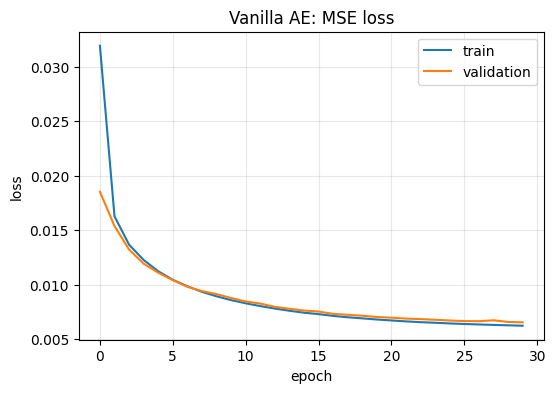

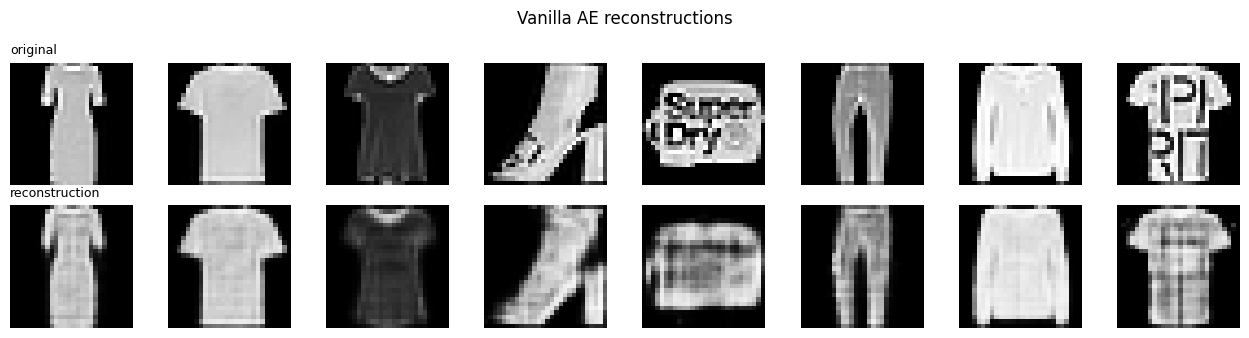

In [ ]:
LATENT_DIM = 64
EPOCHS = 30
LR = 1e-3
BATCH_SIZE = 128

def mse_loss_fn(model, x):
    """Plain reconstruction loss: mean squared error between pixels."""
    recon, _ = model(x)
    return F.mse_loss(recon, x)


if __name__ == "__main__":
    set_seed()
    device = get_device()
    train_loader, val_loader, test_loader = get_dataloaders(BATCH_SIZE)

    model = VanillaAE(latent_dim=LATENT_DIM)
    print(model)
    print("Parameters:", sum(p.numel() for p in model.parameters()))

    history = fit(model, mse_loss_fn, train_loader, val_loader,
                  epochs=EPOCHS, lr=LR, device=device, name="vanilla_ae")

    results = evaluate_recon(model, test_loader, device)
    avg_epoch = sum(history["epoch_time"]) / len(history["epoch_time"])
    print(f"\nTEST  MSE: {results['mse']:.5f} | PSNR: {results['psnr']:.2f} dB "
          f"| SSIM: {results['ssim']:.4f} | avg train time/epoch: {avg_epoch:.2f}s")

    plot_loss_curves(history, "Vanilla AE: MSE loss")
    show_reconstructions(model, test_loader, device, n=8, title="Vanilla AE reconstructions")

# Step 3: MLP Classifier Analysis (section 2)

can a classifier generate images?

### Model

In [ ]:
class MLPClassifier(nn.Module):
    """
    Discriminative MLP:  784 -> 256 -> 64 -> 10   (hidden sizes mirror the AE encoder)

    z_MLP is the 64-d feature vector just before the final classification layer.
    Weights follow PyTorch's convention: fcX.weight has shape [out, in].
    """

    def __init__(self, latent_dim: int = 64, n_classes: int = 10):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, latent_dim)
        self.fc3 = nn.Linear(latent_dim, n_classes)

    def activations(self, x):
        h1 = F.relu(self.fc1(x.flatten(1)))   # [B, 256]
        z = F.relu(self.fc2(h1))              # [B, 64]  = z_MLP
        return h1, z

    def features(self, x):
        return self.activations(x)[1]

    def forward(self, x):
        return self.fc3(self.features(x))     # class logits [B, 10]


class FrozenLatentDecoder(nn.Module):
    """
    Frozen MLP classifier (encoder) + a trainable decoder 64 -> 256 -> 784.
    Only the decoder learns. forward() returns (recon, z) like VanillaAE, so
    fit() and evaluate_recon() work unchanged.
    """

    def __init__(self, classifier: MLPClassifier, latent_dim: int = 64):
        super().__init__()
        self.classifier = classifier
        for p in self.classifier.parameters():
            p.requires_grad = False
        self.classifier.eval()

        # same decoder architecture as VanillaAE -> a fair comparison
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid(),
        )

    def train(self, mode: bool = True):
        super().train(mode)
        self.classifier.eval()      # classifier stays in eval mode no matter what
        return self

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        with torch.no_grad():
            z = self.classifier.features(x)
        return self.decode(z), z

### MLP Analysis

In [ ]:
# ------------------------------------------------ Stage 2: class -> pixels
@torch.no_grad()
def topdown_from_class(clf, device, n_classes=10):
    """x_hat = Sigmoid(W1^T ReLU(W2^T ReLU(W3^T y_c))) for every one-hot class y_c."""
    W1, W2, W3 = clf.fc1.weight, clf.fc2.weight, clf.fc3.weight  # [256,784] [64,256] [10,64]
    Y = torch.eye(n_classes, device=device)                      # one-hot rows
    z_hat = F.relu(Y @ W3)                                       # [10, 64]
    h1_hat = F.relu(z_hat @ W2)                                  # [10, 256]
    return torch.sigmoid(h1_hat @ W1).view(-1, 1, 28, 28)        # [10, 1, 28, 28]


# ------------------------------------------------ Stage 3: z_MLP -> pixels
@torch.no_grad()
def transpose_from_latent(clf, z):
    """x_hat = Sigmoid(W1^T ReLU(W2^T z_MLP))."""
    W1, W2 = clf.fc1.weight, clf.fc2.weight
    h1_hat = F.relu(z @ W2)
    return torch.sigmoid(h1_hat @ W1).view(-1, 1, 28, 28)


@torch.no_grad()
def eval_transpose_projection(clf, loader, device):
    """MSE / PSNR / SSIM of the transpose projection against the real test images."""
    clf.eval()
    mse_sum = psnr_sum = ssim_sum = 0.0
    count = 0
    for x, _ in loader:
        x = x.to(device)
        x_hat = transpose_from_latent(clf, clf.features(x))
        mse = ((x_hat - x) ** 2).mean(dim=(1, 2, 3))
        psnr = 10 * torch.log10(1.0 / mse.clamp_min(1e-10))
        mse_sum += mse.sum().item()
        psnr_sum += psnr.sum().item()
        ssim_sum += ssim_batch(x, x_hat).sum().item()
        count += x.size(0)
    return {"mse": mse_sum / count, "psnr": psnr_sum / count, "ssim": ssim_sum / count}


# ------------------------------------------------ evidence about the weights
@torch.no_grad()
def weight_diagnostics(clf):
    """
    For each weight matrix W [out, in] report its rank and how far W^T is from
    being an inverse. If W^T were W^-1 we would have W W^T = I (and W^T W = I).
    Errors are relative Frobenius distances to the identity; 0 would be perfect.
    """
    rows = []
    for name, layer in [("W1", clf.fc1), ("W2", clf.fc2), ("W3", clf.fc3)]:
        W = layer.weight.detach().cpu()
        out_dim, in_dim = W.shape
        eye_out, eye_in = torch.eye(out_dim), torch.eye(in_dim)
        rows.append({
            "layer": name,
            "shape": tuple(W.shape),
            "rank": int(torch.linalg.matrix_rank(W).item()),
            "err_WWt": ((W @ W.T - eye_out).norm() / eye_out.norm()).item(),
            "err_WtW": ((W.T @ W - eye_in).norm() / eye_in.norm()).item(),
        })
    return rows


@torch.no_grad()
def relu_zero_fraction(clf, loader, device):
    """Fraction of hidden activations that ReLU set to exactly 0 (information thrown away)."""
    clf.eval()
    zeros_h1 = zeros_z = n_h1 = n_z = 0
    for x, _ in loader:
        h1, z = clf.activations(x.to(device))
        zeros_h1 += (h1 == 0).sum().item()
        zeros_z += (z == 0).sum().item()
        n_h1 += h1.numel()
        n_z += z.numel()
    return {"h1_zero_frac": zeros_h1 / n_h1, "z_zero_frac": zeros_z / n_z}


# ------------------------------------------------ Stage 5: latent sampling
@torch.no_grad()
def collect_latents(encode_fn, loader, device):
    """Run encode_fn over a loader and stack all latent vectors -> [N, latent_dim]."""
    zs = [encode_fn(x.to(device)).cpu() for x, _ in loader]
    return torch.cat(zs)


@torch.no_grad()
def sample_diag_gaussian(Z, n, seed=42):
    """z_rand ~ N(mu_z, diag(sigma_z^2)), with mu_z and sigma_z estimated from Z."""
    g = torch.Generator().manual_seed(seed)
    mu, sigma = Z.mean(dim=0), Z.std(dim=0)
    return mu + sigma * torch.randn(n, Z.size(1), generator=g)

### Run MLP Experiment


=== Stage 1: MLP classifier (784 -> 256 -> 64 -> 10) ===
[mlp_classifier] epoch   1/30 | train 0.5937 | val loss 0.4584 | val acc 0.8320 | 7.9s
[mlp_classifier] epoch   2/30 | train 0.4106 | val loss 0.3926 | val acc 0.8583 | 7.3s
[mlp_classifier] epoch   3/30 | train 0.3611 | val loss 0.3607 | val acc 0.8673 | 6.9s
[mlp_classifier] epoch   4/30 | train 0.3376 | val loss 0.3767 | val acc 0.8603 | 7.8s
[mlp_classifier] epoch   5/30 | train 0.3159 | val loss 0.3404 | val acc 0.8760 | 6.3s
[mlp_classifier] epoch   6/30 | train 0.2970 | val loss 0.3366 | val acc 0.8764 | 7.9s
[mlp_classifier] epoch   7/30 | train 0.2852 | val loss 0.3249 | val acc 0.8813 | 6.3s
[mlp_classifier] epoch   8/30 | train 0.2758 | val loss 0.3288 | val acc 0.8797 | 8.1s
[mlp_classifier] epoch   9/30 | train 0.2643 | val loss 0.3146 | val acc 0.8846 | 6.2s
[mlp_classifier] epoch  10/30 | train 0.2554 | val loss 0.3160 | val acc 0.8860 | 7.5s
[mlp_classifier] epoch  11/30 | train 0.2438 | val loss 0.3235 | val acc

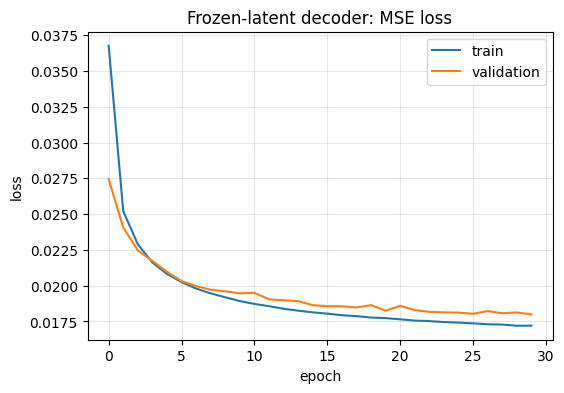


Model                              MSE   PSNR (dB)      SSIM
Frozen z_MLP + decoder         0.01786       18.30    0.5940
Vanilla AE (z_AE)              0.00651       22.99    0.7889

=== Stage 5: sample z ~ N(mu_z, diag(sigma_z^2)) ===


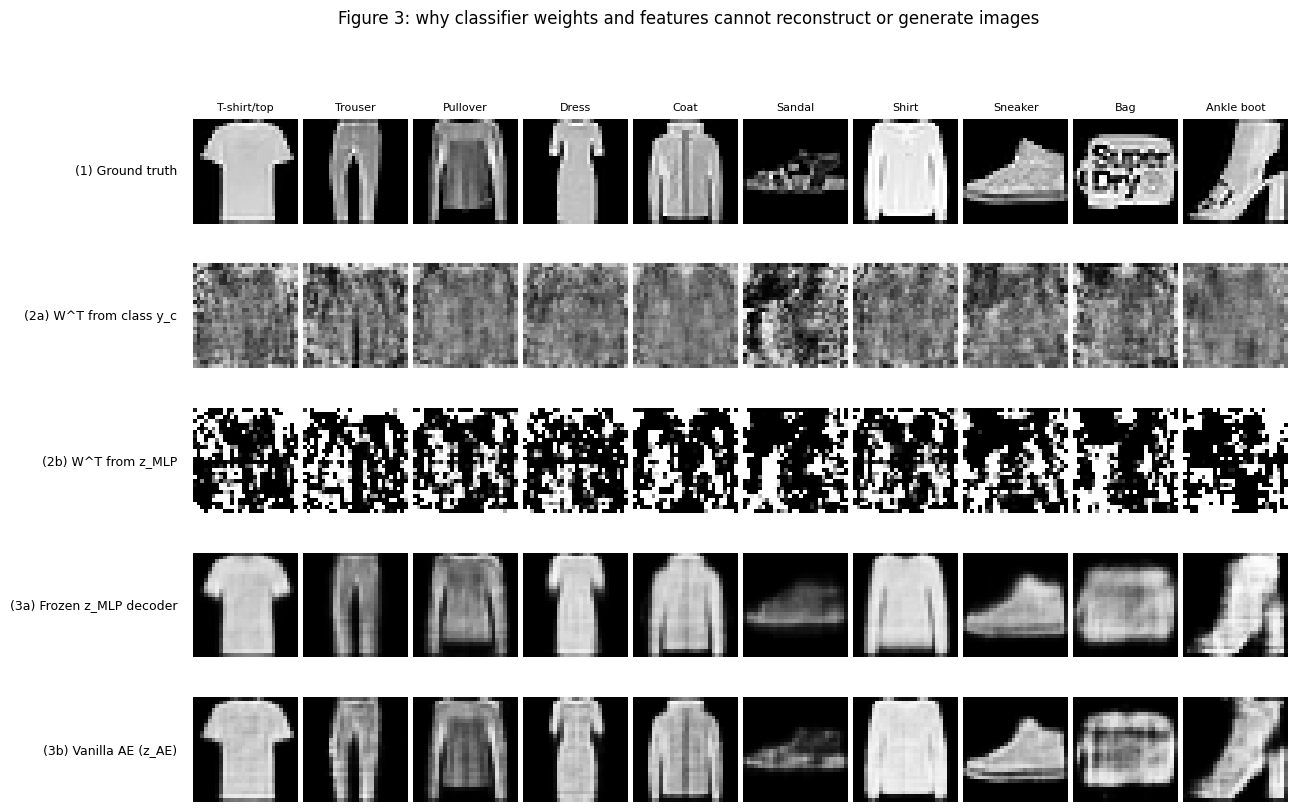

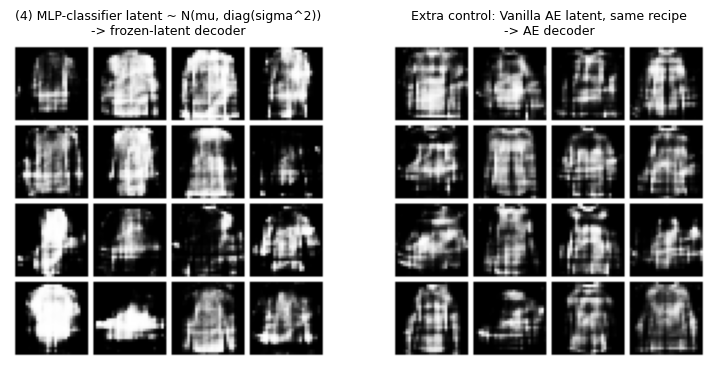


Saved figures/ and results/section2_results.json


In [ ]:
BATCH_SIZE = 128
LATENT_DIM = 64
EPOCHS = 30
LR = 1e-3
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)


# ----------------------------------------------------------------- helpers
def one_per_class(loader, device):
    """First test image of each of the 10 classes -> tensor [10, 1, 28, 28]."""
    found = {}
    for x, y in loader:
        for img, label in zip(x, y):
            found.setdefault(int(label), img)
        if len(found) == 10:
            break
    return torch.stack([found[c] for c in range(10)]).to(device)


def plot_rows(rows, labels, path, title):
    """rows: list of [10,1,28,28] tensors. One matplotlib row per tensor."""
    fig, axes = plt.subplots(len(rows), 10, figsize=(15, 1.7 * len(rows) + 0.8))
    for r, imgs in enumerate(rows):
        for c in range(10):
            ax = axes[r, c]
            ax.imshow(imgs[c].squeeze().detach().cpu(), cmap="gray", vmin=0, vmax=1)
            ax.axis("off")
            if r == 0:
                ax.set_title(CLASS_NAMES[c], fontsize=8)
        axes[r, 0].text(-0.15, 0.5, labels[r], transform=axes[r, 0].transAxes,
                        ha="right", va="center", fontsize=9)
    fig.suptitle(title)
    plt.subplots_adjust(left=0.17, wspace=0.05, hspace=0.05)
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


def grid_image(imgs16):
    return make_grid(imgs16.detach().cpu(), nrow=4, padding=2, pad_value=1.0)[0]


if __name__ == "__main__":
    set_seed()
    device = get_device()
    train_loader, val_loader, test_loader = get_dataloaders(BATCH_SIZE)
    results = {}

    # ================= Stage 1: train the MLP classifier =================
    print("\n=== Stage 1: MLP classifier (784 -> 256 -> 64 -> 10) ===")
    clf = MLPClassifier(latent_dim=LATENT_DIM)
    hist = fit_classifier(clf, train_loader, val_loader, EPOCHS, LR, device, "mlp_classifier")
    test_acc = evaluate_accuracy(clf, test_loader, device)
    results["classifier_test_acc"] = test_acc
    print(f"TEST accuracy: {test_acc * 100:.2f}%")
    if test_acc < 0.88:
        print("WARNING: below 88%. Train longer or tune before continuing.")
    for p in clf.parameters():       # freeze: from here on the classifier never changes
        p.requires_grad = False
    clf.eval()

    # ---- evidence about the weights (supports the "W^T != W^-1" argument)
    print("\nWeight diagnostics (0 would mean W^T is a perfect inverse):")
    diag = weight_diagnostics(clf)
    for d in diag:
        print(f"  {d['layer']} shape={d['shape']}  rank={d['rank']}  "
              f"||WW^T-I||/||I||={d['err_WWt']:.2f}  ||W^TW-I||/||I||={d['err_WtW']:.2f}")
    zf = relu_zero_fraction(clf, test_loader, device)
    print(f"ReLU zeros: {zf['h1_zero_frac'] * 100:.1f}% of hidden-1, "
          f"{zf['z_zero_frac'] * 100:.1f}% of z_MLP (information deleted)")
    results["weight_diagnostics"] = diag
    results["relu_zero_fraction"] = zf

    # ================= Stage 2: top-down transpose from class vectors =================
    print("\n=== Stage 2: class one-hot -> pixels via transposed weights ===")
    x_cls = topdown_from_class(clf, device)             # [10,1,28,28]

    # ================= Stage 3: latent transpose projection =================
    print("=== Stage 3: z_MLP -> pixels via transposed weights ===")
    x_samples = one_per_class(test_loader, device)       # one real image per class
    x_lat = transpose_from_latent(clf, clf.features(x_samples))
    t3 = eval_transpose_projection(clf, test_loader, device)
    results["stage3_transpose_projection"] = t3
    print(f"Test MSE {t3['mse']:.4f} | PSNR {t3['psnr']:.2f} dB | SSIM {t3['ssim']:.4f}")

    # ================= Stage 4: frozen latent decoding vs Vanilla AE =================
    print("\n=== Stage 4: decoder trained on FROZEN z_MLP ===")
    frozen = FrozenLatentDecoder(clf, latent_dim=LATENT_DIM)
    hist4 = fit(frozen, mse_recon_loss, train_loader, val_loader,
                epochs=EPOCHS, lr=LR, device=device, name="frozen_latent_decoder")
    plot_loss_curves(hist4, "Frozen-latent decoder: MSE loss")
    r_frozen = evaluate_recon(frozen, test_loader, device)

    ae_path = os.path.join("checkpoints", "vanilla_ae.pt")
    if not os.path.exists(ae_path):
        raise FileNotFoundError("checkpoints/vanilla_ae.pt not found. Run run_vanilla_ae.py first.")
    ae = VanillaAE(latent_dim=LATENT_DIM).to(device)
    ae.load_state_dict(torch.load(ae_path, map_location=device))
    ae.eval()
    r_ae = evaluate_recon(ae, test_loader, device)

    print(f"\n{'Model':<28}{'MSE':>10}{'PSNR (dB)':>12}{'SSIM':>10}")
    print(f"{'Frozen z_MLP + decoder':<28}{r_frozen['mse']:>10.5f}{r_frozen['psnr']:>12.2f}{r_frozen['ssim']:>10.4f}")
    print(f"{'Vanilla AE (z_AE)':<28}{r_ae['mse']:>10.5f}{r_ae['psnr']:>12.2f}{r_ae['ssim']:>10.4f}")
    results["stage4_frozen_decoder"] = r_frozen
    results["stage4_vanilla_ae"] = r_ae

    # ================= Stage 5: Gaussian prior sampling =================
    print("\n=== Stage 5: sample z ~ N(mu_z, diag(sigma_z^2)) ===")
    Z_mlp = collect_latents(clf.features, test_loader, device)
    z_rand = sample_diag_gaussian(Z_mlp, 16).to(device)
    with torch.no_grad():
        samples_mlp = frozen.decode(z_rand)

    # Extra control (not required by the guide): same recipe on the Vanilla AE's latent.
    Z_ae = collect_latents(ae.encode, test_loader, device)
    z_rand_ae = sample_diag_gaussian(Z_ae, 16).to(device)
    with torch.no_grad():
        samples_ae = ae.decode(z_rand_ae)

    # ================= Figure 3 =================
    with torch.no_grad():
        recon_frozen = frozen(x_samples)[0]
        recon_ae = ae(x_samples)[0]
    plot_rows(
        [x_samples, x_cls, x_lat, recon_frozen, recon_ae],
        ["(1) Ground truth", "(2a) W^T from class y_c", "(2b) W^T from z_MLP",
         "(3a) Frozen z_MLP decoder", "(3b) Vanilla AE (z_AE)"],
        "figures/fig3_panels_1_to_3.png",
        "Figure 3: why classifier weights and features cannot reconstruct or generate images",
    )

    fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
    axes[0].imshow(grid_image(samples_mlp), cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("(4) MLP-classifier latent ~ N(mu, diag(sigma^2))\n-> frozen-latent decoder", fontsize=9)
    axes[1].imshow(grid_image(samples_ae), cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Extra control: Vanilla AE latent, same recipe\n-> AE decoder", fontsize=9)
    for ax in axes:
        ax.axis("off")
    fig.savefig("figures/fig3_panel_4_sampling.png", dpi=200, bbox_inches="tight")
    plt.show()

    with open("results/section2_results.json", "w") as f:
        json.dump(results, f, indent=2)
    print("\nSaved figures/ and results/section2_results.json")

# Step 4: Sparse AE

### Model

In [ ]:
class SparseAE(VanillaAE):
    """
    Same architecture and weights layout as VanillaAE (784 -> 256 -> 64 -> 256 -> 784).
    The only difference is the training loss: an L1 penalty on the 256-d hidden
    code h (the ReLU output of the first encoder layer) pushes most of its units to 0.

    forward() returns (reconstruction, z, h); h is needed by the sparsity loss.
    """

    def forward(self, x):
        h = self.encoder[:3](x)      # Flatten -> Linear(784,256) -> ReLU  => sparse code h [B,256]
        z = self.encoder[3](h)       # Linear(256,64)                      => bottleneck z [B,64]
        return self.decode(z), z, h

### Run Sparse AE Model


=== Sparse AE, lambda = 1e-05 (sparse_ae_lam1e-05) ===
[sparse_ae_lam1e-05] epoch   1/30 | train 0.03322 | val 0.01983 | 6.9s
[sparse_ae_lam1e-05] epoch   2/30 | train 0.01755 | val 0.01604 | 8.1s
[sparse_ae_lam1e-05] epoch   3/30 | train 0.01483 | val 0.01419 | 6.6s
[sparse_ae_lam1e-05] epoch   4/30 | train 0.01340 | val 0.01310 | 8.1s
[sparse_ae_lam1e-05] epoch   5/30 | train 0.01241 | val 0.01237 | 6.6s
[sparse_ae_lam1e-05] epoch   6/30 | train 0.01164 | val 0.01161 | 7.8s
[sparse_ae_lam1e-05] epoch   7/30 | train 0.01106 | val 0.01111 | 7.2s
[sparse_ae_lam1e-05] epoch   8/30 | train 0.01058 | val 0.01064 | 6.9s
[sparse_ae_lam1e-05] epoch   9/30 | train 0.01019 | val 0.01040 | 8.1s
[sparse_ae_lam1e-05] epoch  10/30 | train 0.00984 | val 0.00997 | 6.5s
[sparse_ae_lam1e-05] epoch  11/30 | train 0.00954 | val 0.00967 | 8.2s
[sparse_ae_lam1e-05] epoch  12/30 | train 0.00927 | val 0.00947 | 6.5s
[sparse_ae_lam1e-05] epoch  13/30 | train 0.00903 | val 0.00925 | 8.2s
[sparse_ae_lam1e-05] 

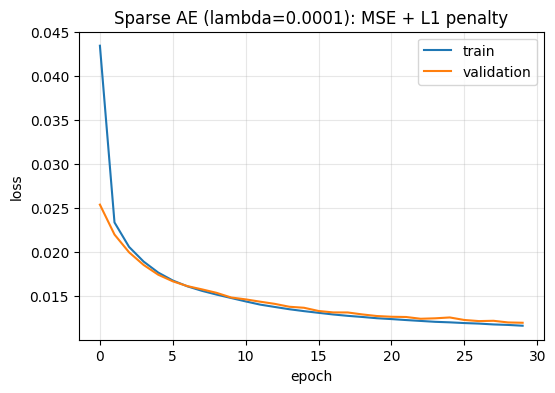

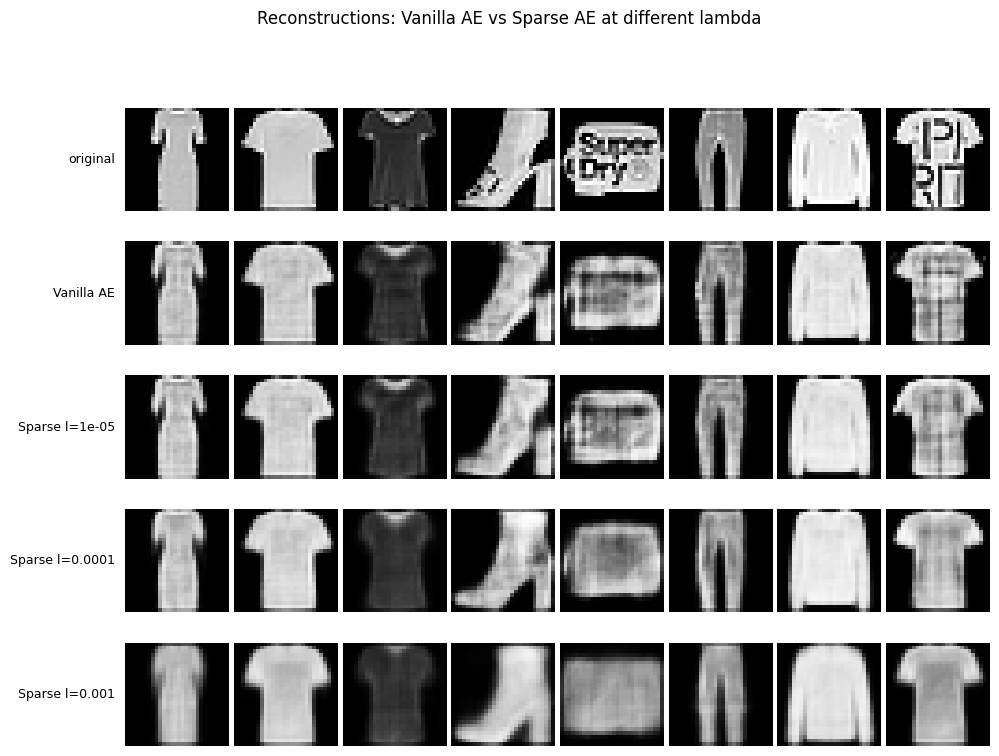

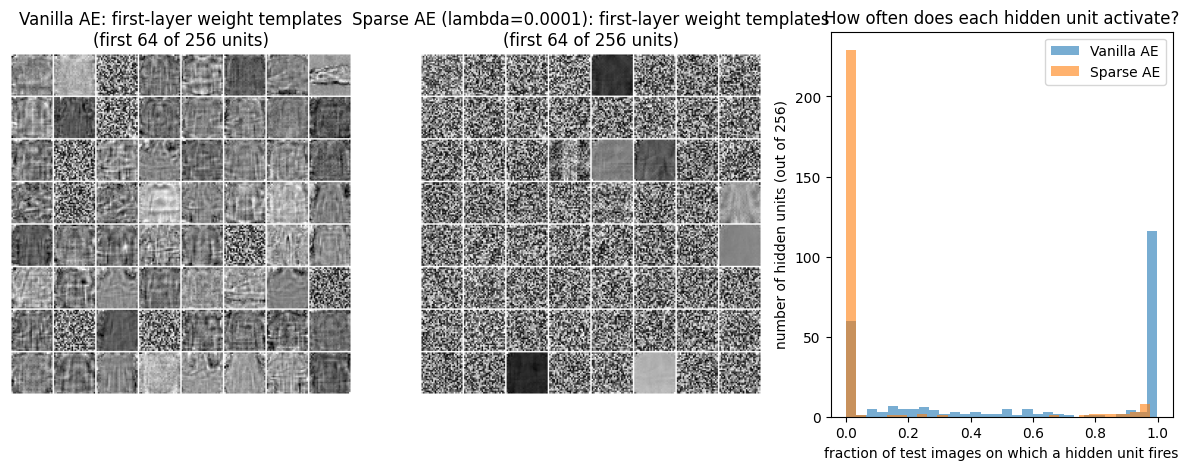


Saved figures/ and results/sparse_ae_results.json


In [ ]:
LATENT_DIM = 64
EPOCHS = 30
LR = 1e-3
BATCH_SIZE = 128
LAMBDAS = [1e-5, 1e-4, 1e-3]   # weak / medium / strong sparsity penalty
MAIN_LAMBDA = 1e-4             # the Sparse AE used in the rest of the project
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)


def filter_grid(model, n=64):
    """First-layer weights: each of the first n hidden units as a 28x28 'template' image."""
    W = model.encoder[1].weight.detach().cpu()[:n].view(n, 1, 28, 28)
    return make_grid(W, nrow=8, normalize=True, scale_each=True, padding=1, pad_value=1.0)[0]


if __name__ == "__main__":
    device = get_device()
    train_loader, val_loader, test_loader = get_dataloaders(BATCH_SIZE)

    # ---- reference: Vanilla AE from Step 2
    ae_path = os.path.join("checkpoints", "vanilla_ae.pt")
    if not os.path.exists(ae_path):
        raise FileNotFoundError("checkpoints/vanilla_ae.pt not found. Run run_vanilla_ae.py first.")
    vanilla = VanillaAE(LATENT_DIM).to(device)
    vanilla.load_state_dict(torch.load(ae_path, map_location=device))
    vanilla.eval()
    results = {"vanilla_ae": {**evaluate_recon(vanilla, test_loader, device),
                              **sparsity_stats(hidden_activations(vanilla, test_loader, device))}}

    # ---- train one Sparse AE per lambda
    models, histories = {}, {}
    for lam in LAMBDAS:
        set_seed()
        name = "sparse_ae" if lam == MAIN_LAMBDA else f"sparse_ae_lam{lam:g}"
        print(f"\n=== Sparse AE, lambda = {lam:g} ({name}) ===")
        model = SparseAE(LATENT_DIM)
        hist = fit(model, sparse_ae_loss(lam), train_loader, val_loader,
                   epochs=EPOCHS, lr=LR, device=device, name=name)
        model.eval()
        models[lam], histories[lam] = model, hist
        results[name] = {
            "lambda": lam,
            **evaluate_recon(model, test_loader, device),
            **sparsity_stats(hidden_activations(model, test_loader, device)),
            "avg_epoch_time": sum(hist["epoch_time"]) / len(hist["epoch_time"]),
        }

    # ---- comparison table
    print(f"\n{'Model':<22}{'MSE':>9}{'PSNR':>8}{'SSIM':>8}{'active%':>9}{'units/img':>10}{'dead':>6}")
    for name, r in results.items():
        print(f"{name:<22}{r['mse']:>9.5f}{r['psnr']:>8.2f}{r['ssim']:>8.4f}"
              f"{r['active_fraction'] * 100:>9.1f}{r['mean_active_units']:>10.1f}{r['dead_units']:>6d}")

    # ---- figures
    main = models[MAIN_LAMBDA]
    plot_loss_curves(histories[MAIN_LAMBDA], f"Sparse AE (lambda={MAIN_LAMBDA:g}): MSE + L1 penalty")

    compare = {"Vanilla AE": vanilla}
    for lam in LAMBDAS:
        compare[f"Sparse l={lam:g}"] = models[lam]
    plot_recon_comparison(compare, test_loader, device, n=8,
                          path="figures/sparse_ae_lambda_comparison.png",
                          title="Reconstructions: Vanilla AE vs Sparse AE at different lambda")

    # Hidden-layer features: learned templates + how often each unit fires
    H_van = hidden_activations(vanilla, test_loader, device)
    H_spa = hidden_activations(main, test_loader, device)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(filter_grid(vanilla), cmap="gray")
    axes[0].set_title("Vanilla AE: first-layer weight templates\n(first 64 of 256 units)")
    axes[1].imshow(filter_grid(main), cmap="gray")
    axes[1].set_title(f"Sparse AE (lambda={MAIN_LAMBDA:g}): first-layer weight templates\n(first 64 of 256 units)")
    for ax in axes[:2]:
        ax.axis("off")
    axes[2].hist((H_van > 1e-6).float().mean(0).numpy(), bins=30, alpha=0.6, label="Vanilla AE")
    axes[2].hist((H_spa > 1e-6).float().mean(0).numpy(), bins=30, alpha=0.6, label="Sparse AE")
    axes[2].set_xlabel("fraction of test images on which a hidden unit fires")
    axes[2].set_ylabel("number of hidden units (out of 256)")
    axes[2].set_title("How often does each hidden unit activate?")
    axes[2].legend()
    fig.savefig("figures/sparse_vs_vanilla_features.png", dpi=200, bbox_inches="tight")
    plt.show()

    with open("results/sparse_ae_results.json", "w") as f:
        json.dump(results, f, indent=2)
    print("\nSaved figures/ and results/sparse_ae_results.json")

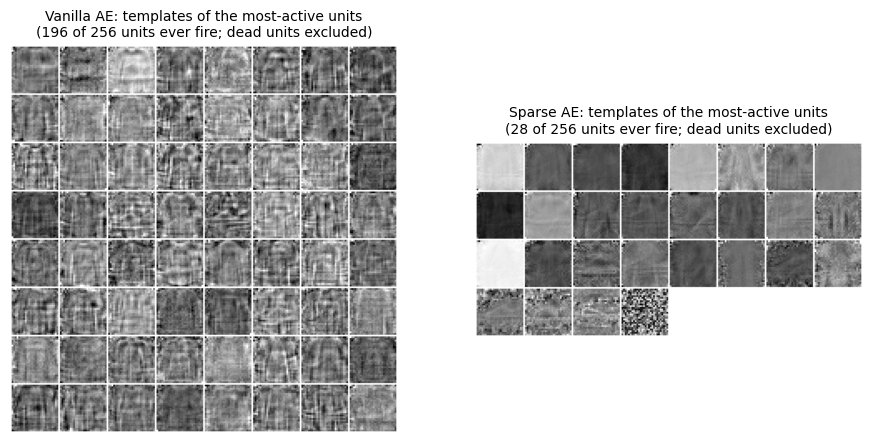

In [ ]:
def load(cls, name, device):
    model = cls(64).to(device)
    model.load_state_dict(torch.load(f"checkpoints/{name}.pt", map_location=device))
    return model.eval()


def alive_template_grid(model, loader, device, n=64):
    """Templates (first-layer weights) of the n most frequently firing units, dead ones excluded."""
    H = hidden_activations(model, loader, device)
    freq = (H > 1e-6).float().mean(dim=0)                    # how often each unit fires
    alive = torch.nonzero(freq > 0).flatten()
    order = alive[torch.argsort(freq[alive], descending=True)][:n]
    W = model.encoder[1].weight.detach().cpu()[order].view(-1, 1, 28, 28)
    grid = make_grid(W, nrow=8, normalize=True, scale_each=True, padding=1, pad_value=1.0)[0]
    return grid, len(alive)


if __name__ == "__main__":
    device = get_device()
    _, _, test_loader = get_dataloaders(128)
    vanilla = load(VanillaAE, "vanilla_ae", device)
    sparse = load(SparseAE, "sparse_ae", device)

    fig, axes = plt.subplots(1, 2, figsize=(11, 5.6))
    for ax, model, label in [(axes[0], vanilla, "Vanilla AE"), (axes[1], sparse, "Sparse AE")]:
        grid, n_alive = alive_template_grid(model, test_loader, device)
        ax.imshow(grid, cmap="gray")
        ax.axis("off")
        ax.set_title(f"{label}: templates of the most-active units\n"
                     f"({n_alive} of 256 units ever fire; dead units excluded)", fontsize=10)
    fig.savefig("figures/sparse_vs_vanilla_alive_templates.png", dpi=200, bbox_inches="tight")
    plt.show()

# Step 5: VAE

### Model

In [ ]:
class VAE(nn.Module):
  def __init__(self, latent_dim: int = 64):
      super().__init__()
      self.latent_dim = latent_dim
      self.enc = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU())
      self.fc_mu = nn.Linear(256, latent_dim)
      self.fc_logvar = nn.Linear(256, latent_dim)   # predict log(sigma^2) for numerical stability
      self.decoder = nn.Sequential(
          nn.Linear(latent_dim, 256), nn.ReLU(),
          nn.Linear(256, 784), nn.Sigmoid(),
      )

  def encode(self, x):
      h = self.enc(x)
      return self.fc_mu(h), self.fc_logvar(h)

  def reparameterize(self, mu, logvar):
      if self.training:
          std = torch.exp(0.5 * logvar)
          eps = torch.randn_like(std)     # all the randomness lives in eps...
          return mu + eps * std           # ...so gradients can flow through mu and std
      return mu

  def decode(self, z):
      return self.decoder(z).view(-1, 1, 28, 28)

  def forward(self, x):
      mu, logvar = self.encode(x)
      z = self.reparameterize(mu, logvar)
      return self.decode(z), mu, logvar

  @torch.no_grad()
  def sample(self, n, seed=None):
      """Generate n brand-new images from the prior z ~ N(0, I)."""
      dev = next(self.parameters()).device
      g = torch.Generator(device=dev)
      if seed is not None:
          g.manual_seed(seed)
      z = torch.randn(n, self.latent_dim, generator=g, device=dev)
      return self.decode(z)

### Run VAE Model

Parameters: 451984
[vae] epoch   1/30 | train 299.84908 | val 268.89831 | 7.6s
[vae] epoch   2/30 | train 267.78816 | val 261.70911 | 7.9s
[vae] epoch   3/30 | train 258.67118 | val 252.18004 | 6.6s
[vae] epoch   4/30 | train 253.06546 | val 247.97946 | 9.0s
[vae] epoch   5/30 | train 250.05349 | val 245.44266 | 6.8s
[vae] epoch   6/30 | train 248.13820 | val 243.78155 | 8.3s
[vae] epoch   7/30 | train 246.86504 | val 242.79237 | 7.4s
[vae] epoch   8/30 | train 245.95044 | val 241.87320 | 7.3s
[vae] epoch   9/30 | train 245.17256 | val 240.84616 | 8.4s
[vae] epoch  10/30 | train 244.64523 | val 240.73492 | 6.8s
[vae] epoch  11/30 | train 244.20925 | val 239.73055 | 8.6s
[vae] epoch  12/30 | train 243.77233 | val 239.75823 | 7.1s
[vae] epoch  13/30 | train 243.41290 | val 239.48346 | 7.8s
[vae] epoch  14/30 | train 243.18269 | val 238.59239 | 8.0s
[vae] epoch  15/30 | train 242.87372 | val 238.81364 | 7.2s
[vae] epoch  16/30 | train 242.64293 | val 238.19405 | 8.3s
[vae] epoch  17/30 | 

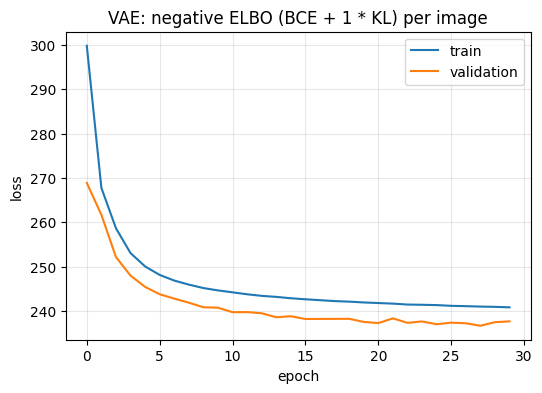

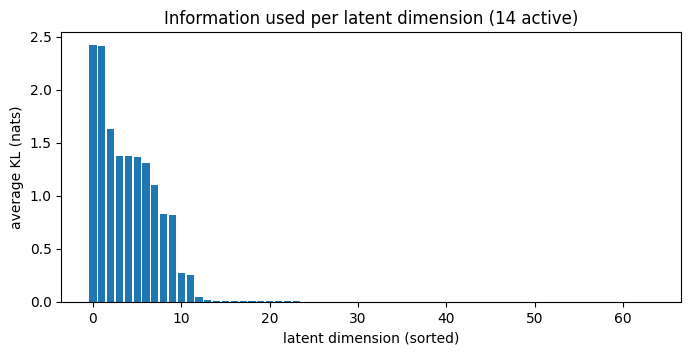

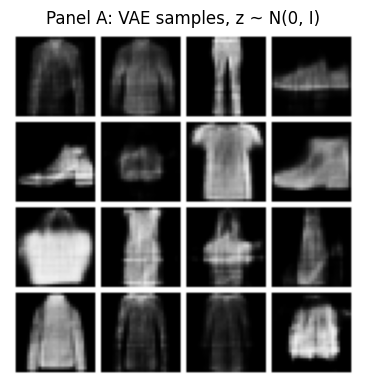


VAE encoded means over the test set: mean -0.000, std 0.409
Vanilla AE latent over the test set: mean -0.129, std 1.589


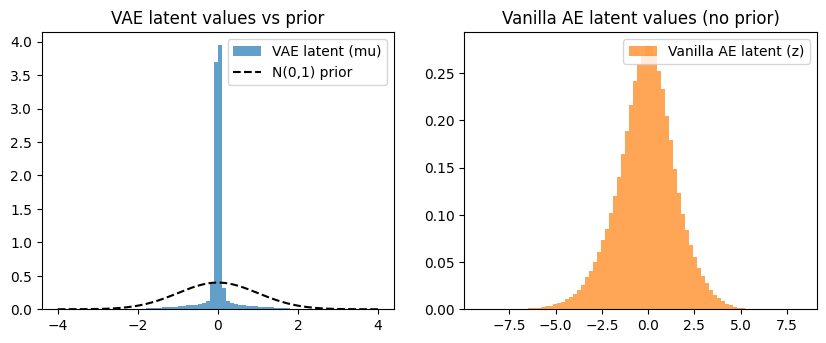


Model                MSE   PSNR (dB)     SSIM
Vanilla AE       0.00651       22.99   0.7889
Sparse AE        0.01115       20.49   0.6842
VAE              0.01334       19.60   0.6454


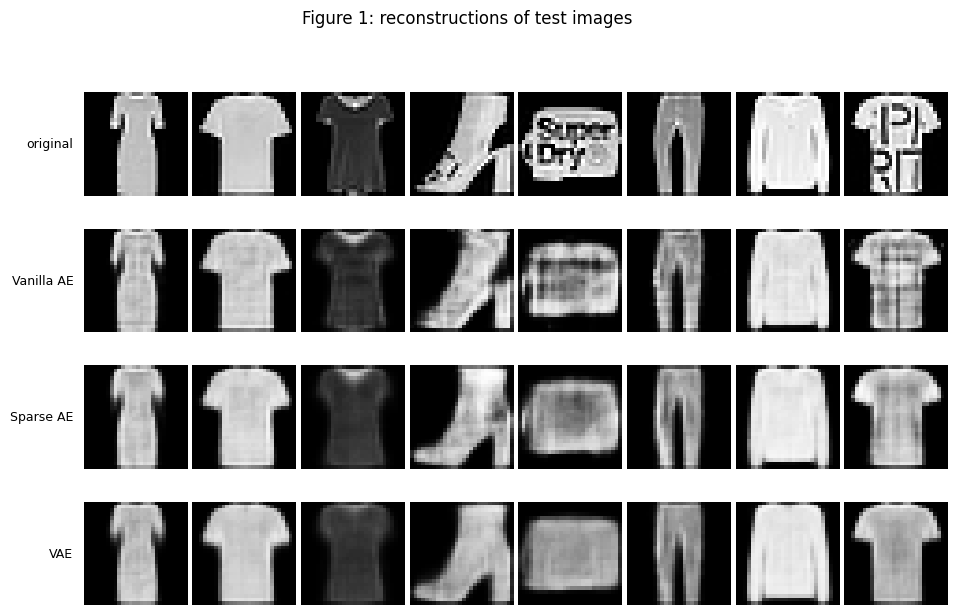


Saved figures/ and results/vae_results.json


In [ ]:
LATENT_DIM = 64
EPOCHS = 30
LR = 1e-3
BATCH_SIZE = 128
BETA = 1.0                    # weight of the KL term (1.0 = the standard VAE)
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)


def load_if_exists(model, name, device):
    path = os.path.join("checkpoints", f"{name}.pt")
    if not os.path.exists(path):
        return None
    model.load_state_dict(torch.load(path, map_location=device))
    return model.to(device).eval()


if __name__ == "__main__":
    set_seed()
    device = get_device()
    train_loader, val_loader, test_loader = get_dataloaders(BATCH_SIZE)

    # ---------------------------------------------------------- train
    model = VAE(latent_dim=LATENT_DIM)
    print("Parameters:", sum(p.numel() for p in model.parameters()))
    history = fit(model, vae_loss(BETA), train_loader, val_loader,
                  epochs=EPOCHS, lr=LR, device=device, name="vae")
    model.eval()

    # ---------------------------------------------------------- evaluate
    rec = evaluate_recon(model, test_loader, device)
    terms = evaluate_vae_terms(model, test_loader, device)
    avg_epoch = sum(history["epoch_time"]) / len(history["epoch_time"])
    kl_dims = torch.tensor(terms["kl_per_dim"])
    n_active = int((kl_dims > 0.01).sum())
    print(f"\nTEST  MSE {rec['mse']:.5f} | PSNR {rec['psnr']:.2f} dB | SSIM {rec['ssim']:.4f}")
    print(f"      BCE term {terms['bce']:.1f} | KL term {terms['kl']:.1f} nats | "
          f"active latent dims (KL > 0.01): {n_active}/{LATENT_DIM}")
    print(f"      avg train time/epoch: {avg_epoch:.2f}s")

    plot_loss_curves(history, f"VAE: negative ELBO (BCE + {BETA:g} * KL) per image")

    # ---------------------------------------------------------- KL per dimension
    order = torch.argsort(kl_dims, descending=True)
    plt.figure(figsize=(8, 3.5))
    plt.bar(range(LATENT_DIM), kl_dims[order].numpy())
    plt.xlabel("latent dimension (sorted)")
    plt.ylabel("average KL (nats)")
    plt.title(f"Information used per latent dimension ({n_active} active)")
    plt.savefig("figures/vae_kl_per_dim.png", dpi=200, bbox_inches="tight")
    plt.show()

    # ---------------------------------------------------------- Figure 2, panel A
    samples = model.sample(16, seed=42)
    grid = make_grid(samples.cpu(), nrow=4, padding=2, pad_value=1.0)[0]
    plt.figure(figsize=(4.5, 4.5))
    plt.imshow(grid, cmap="gray", vmin=0, vmax=1)
    plt.axis("off")
    plt.title("Panel A: VAE samples, z ~ N(0, I)")
    plt.savefig("figures/fig2_panelA_vae_samples.png", dpi=200, bbox_inches="tight")
    plt.show()

    # ---------------------------------------------------------- does the latent look like the prior?
    with torch.no_grad():
        mu_all = torch.cat([model.encode(x.to(device))[0].cpu() for x, _ in test_loader])
    print(f"\nVAE encoded means over the test set: mean {mu_all.mean():.3f}, std {mu_all.std():.3f}")

    ae = load_if_exists(VanillaAE(LATENT_DIM), "vanilla_ae", device)
    fig, axes = plt.subplots(1, 2 if ae is not None else 1, figsize=(10 if ae else 5, 3.6))
    axes = [axes] if ae is None else list(axes)
    xs = torch.linspace(-4, 4, 200)
    axes[0].hist(mu_all.flatten().numpy(), bins=80, range=(-4, 4), density=True, alpha=0.7, label="VAE latent (mu)")
    axes[0].plot(xs, torch.exp(-xs ** 2 / 2) / math.sqrt(2 * math.pi), "k--", label="N(0,1) prior")
    axes[0].set_title("VAE latent values vs prior")
    axes[0].legend()
    if ae is not None:
        with torch.no_grad():
            z_ae = torch.cat([ae.encode(x.to(device)).cpu() for x, _ in test_loader])
        print(f"Vanilla AE latent over the test set: mean {z_ae.mean():.3f}, std {z_ae.std():.3f}")
        axes[1].hist(z_ae.flatten().numpy(), bins=80, density=True, alpha=0.7, color="tab:orange",
                     label="Vanilla AE latent (z)")
        axes[1].set_title("Vanilla AE latent values (no prior)")
        axes[1].legend()
    fig.savefig("figures/latent_distribution.png", dpi=200, bbox_inches="tight")
    plt.show()

    # ---------------------------------------------------------- Figure 1 + Q1 reconstruction table
    results = {"vae": {**rec, **terms, "avg_epoch_time": avg_epoch, "n_active_dims": n_active}}
    sparse = load_if_exists(SparseAE(LATENT_DIM), "sparse_ae", device)
    if ae is not None and sparse is not None:
        results["vanilla_ae"] = evaluate_recon(ae, test_loader, device)
        results["sparse_ae"] = evaluate_recon(sparse, test_loader, device)
        print(f"\n{'Model':<14}{'MSE':>10}{'PSNR (dB)':>12}{'SSIM':>9}")
        for label, key in [("Vanilla AE", "vanilla_ae"), ("Sparse AE", "sparse_ae"), ("VAE", "vae")]:
            r = results[key]
            print(f"{label:<14}{r['mse']:>10.5f}{r['psnr']:>12.2f}{r['ssim']:>9.4f}")
        plot_recon_comparison({"Vanilla AE": ae, "Sparse AE": sparse, "VAE": model},
                              test_loader, device, n=8,
                              path="figures/fig1_reconstruction_grid.png",
                              title="Figure 1: reconstructions of test images")
    else:
        print("\n(Skipped Figure 1: need checkpoints/vanilla_ae.pt and checkpoints/sparse_ae.pt.)")

    with open("results/vae_results.json", "w") as f:
        json.dump(results, f, indent=2)
    print("\nSaved figures/ and results/vae_results.json")

# Step 6: Vanilla GAN

### Model

In [ ]:
class VanillaGenerator(nn.Module):
    """
    Fully connected generator: noise z in R^latent_dim -> 256 -> 512 -> 1024 -> 784.
    forward() returns images in [-1, 1] (Tanh), the usual GAN convention.
    sample() returns images rescaled to [0, 1] so they can be viewed / scored
    like every other model's output.
    """

    def __init__(self, latent_dim: int = 100):
        super().__init__()
        self.latent_dim = latent_dim
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 1024), nn.LeakyReLU(0.2),
            nn.Linear(1024, 784), nn.Tanh(),
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

    @torch.no_grad()
    def sample(self, n, seed=None):
        dev = next(self.parameters()).device
        g = torch.Generator(device=dev)
        if seed is not None:
            g.manual_seed(seed)
        z = torch.randn(n, self.latent_dim, generator=g, device=dev)
        return (self(z) + 1) / 2


class VanillaDiscriminator(nn.Module):
    """
    Fully connected discriminator: 784 -> 1024 -> 512 -> 256 -> 1.
    Outputs a raw score (logit): large positive = "looks real", negative = "looks fake".
    The sigmoid is folded into the loss (BCEWithLogitsLoss) for numerical stability.
    """

    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 1024), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(1024, 512), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(512, 256), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(256, 1),
        )

    def forward(self, x):
        return self.net(x)           # [B, 1] logits

### GAN Analysis

In [ ]:
@torch.no_grad()
def class_histogram(sample_fn, classifier, device, n=2000, batch=500):
    """
    Label generated images with the Step-3 MLP classifier and count each class.
    A healthy generator covers all 10 classes roughly evenly (~10% each);
    mode collapse shows up as a few classes dominating or some missing.
    sample_fn(n) must return images in [0, 1] with shape [n, 1, 28, 28].
    """
    classifier.eval()
    counts = torch.zeros(10, dtype=torch.long)
    done = 0
    while done < n:
        m = min(batch, n - done)
        preds = classifier(sample_fn(m).to(device)).argmax(dim=1).cpu()
        counts += torch.bincount(preds, minlength=10)
        done += m
    probs = counts.float() / counts.sum()
    entropy = -(probs[probs > 0] * probs[probs > 0].log()).sum().item()
    return {
        "counts": counts.tolist(),
        "classes_present": int((counts > 0.02 * n).sum()),   # classes with > 2% of samples
        "entropy_ratio": entropy / torch.log(torch.tensor(10.0)).item(),  # 1.0 = perfectly even
    }


@torch.no_grad()
def pairwise_diversity(images, max_n=500):
    """Mean pairwise L2 distance between images. Compare generated vs real: much lower = less diverse."""
    flat = images[:max_n].flatten(1).float().cpu()
    return torch.pdist(flat).mean().item()

### Run Vanilla GAN Model

Generator params:     1486352
Discriminator params: 1460225
[vanilla_gan] epoch   1/50 | D 0.659 | G 2.716 | D(x) 0.88 | D(G(z)) 0.29 | 8.8s
[vanilla_gan] epoch   2/50 | D 0.723 | G 2.631 | D(x) 0.78 | D(G(z)) 0.24 | 9.9s
[vanilla_gan] epoch   3/50 | D 0.784 | G 2.201 | D(x) 0.75 | D(G(z)) 0.26 | 10.0s
[vanilla_gan] epoch   4/50 | D 0.913 | G 1.830 | D(x) 0.70 | D(G(z)) 0.30 | 8.6s
[vanilla_gan] epoch   5/50 | D 0.912 | G 1.804 | D(x) 0.70 | D(G(z)) 0.30 | 10.1s
[vanilla_gan] epoch   6/50 | D 0.949 | G 1.659 | D(x) 0.68 | D(G(z)) 0.32 | 9.8s
[vanilla_gan] epoch   7/50 | D 0.967 | G 1.593 | D(x) 0.68 | D(G(z)) 0.32 | 8.7s
[vanilla_gan] epoch   8/50 | D 1.002 | G 1.491 | D(x) 0.66 | D(G(z)) 0.34 | 10.0s
[vanilla_gan] epoch   9/50 | D 1.032 | G 1.437 | D(x) 0.65 | D(G(z)) 0.35 | 9.3s
[vanilla_gan] epoch  10/50 | D 1.097 | G 1.296 | D(x) 0.63 | D(G(z)) 0.37 | 9.2s
[vanilla_gan] epoch  11/50 | D 1.134 | G 1.239 | D(x) 0.61 | D(G(z)) 0.39 | 10.0s
[vanilla_gan] epoch  12/50 | D 1.161 | G 1.16

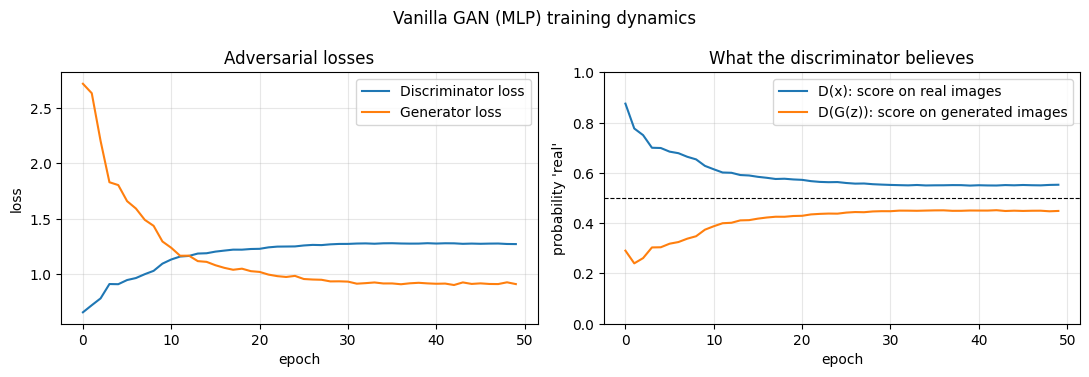

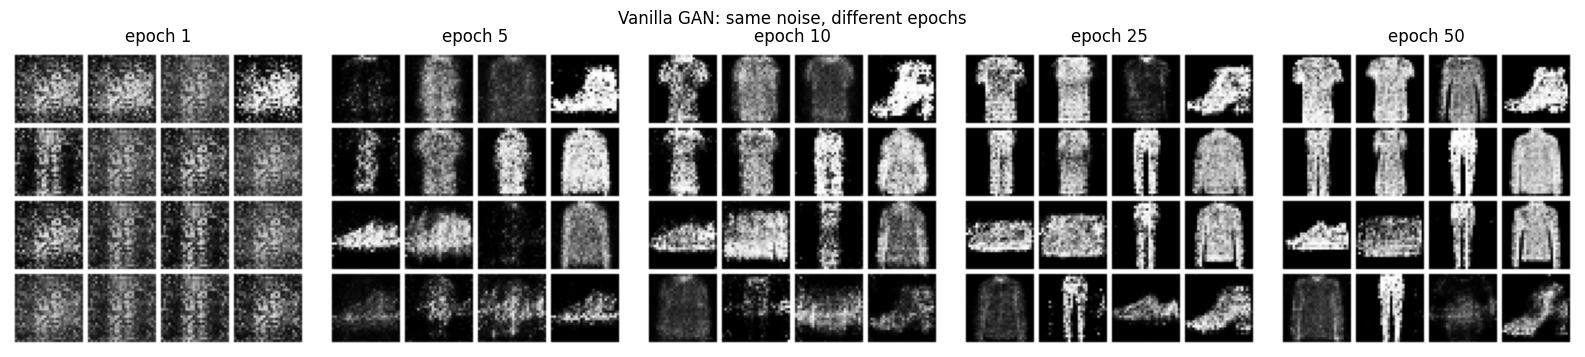

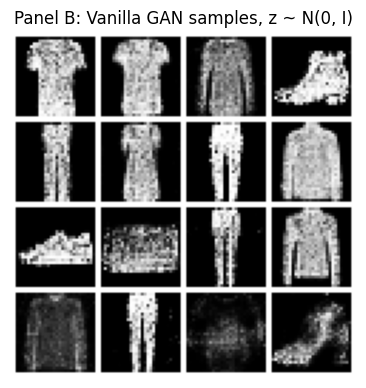


Pairwise diversity (mean L2): real 11.37 | generated 11.01 (ratio 0.97; much lower than 1 suggests mode collapse)
Classes present (>2% of samples): 10/10 | entropy ratio 0.99 (1.0 = perfectly even)


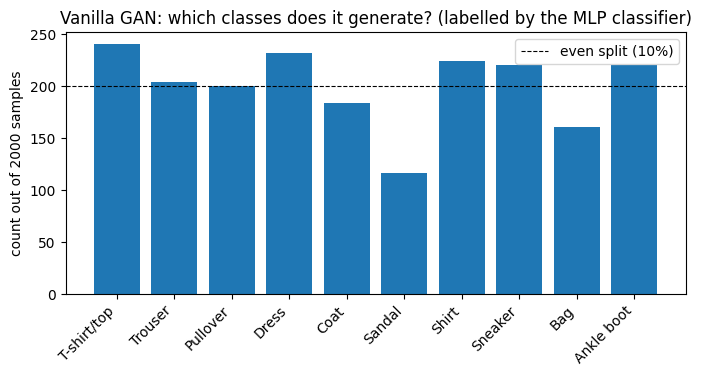


Saved figures/ and results/vanilla_gan_results.json


In [ ]:
LATENT_DIM = 100
EPOCHS = 50
LR = 2e-4
BATCH_SIZE = 128
SNAPSHOT_EPOCHS = (1, 5, 10, 25, 50)
NAME = "vanilla_gan"
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

if __name__ == "__main__":
    set_seed()
    device = get_device()
    train_loader, val_loader, test_loader = get_dataloaders(BATCH_SIZE)

    G = VanillaGenerator(LATENT_DIM)
    D = VanillaDiscriminator()
    print("Generator params:    ", sum(p.numel() for p in G.parameters()))
    print("Discriminator params:", sum(p.numel() for p in D.parameters()))

    # Note: the validation and test sets are NOT used to train a GAN. The test set is
    # used later only for FID (compared against the generated samples).
    history = train_gan(G, D, train_loader, EPOCHS, LR, device, NAME, LATENT_DIM,
                        snapshot_epochs=SNAPSHOT_EPOCHS)
    avg_epoch = sum(history["epoch_time"]) / len(history["epoch_time"])
    print(f"\nAvg train time/epoch: {avg_epoch:.2f}s")

    # ---------------------------------------------------------- training dynamics
    plot_gan_curves(history, "Vanilla GAN (MLP) training dynamics",
                    path="figures/vanilla_gan_curves.png")
    plot_snapshots(history["snapshots"], "Vanilla GAN: same noise, different epochs",
                   path="figures/vanilla_gan_snapshots.png")

    # ---------------------------------------------------------- Figure 2, panel B
    samples = G.sample(16, seed=42)
    grid = make_grid(samples.cpu(), nrow=4, padding=2, pad_value=1.0)[0]
    plt.figure(figsize=(4.5, 4.5))
    plt.imshow(grid, cmap="gray", vmin=0, vmax=1)
    plt.axis("off")
    plt.title("Panel B: Vanilla GAN samples, z ~ N(0, I)")
    plt.savefig("figures/fig2_panelB_vanilla_gan_samples.png", dpi=200, bbox_inches="tight")
    plt.show()

    # ---------------------------------------------------------- mode-collapse diagnostics
    results = {"avg_epoch_time": avg_epoch,
               "final_loss_D": history["loss_D"][-1], "final_loss_G": history["loss_G"][-1],
               "final_D_real": history["D_real"][-1], "final_D_fake": history["D_fake"][-1]}

    real_imgs = torch.cat([x for x, _ in test_loader])[:500]
    fake_imgs = G.sample(500, seed=0).cpu()
    d_real, d_fake = pairwise_diversity(real_imgs), pairwise_diversity(fake_imgs)
    results["diversity_real"], results["diversity_generated"] = d_real, d_fake
    print(f"\nPairwise diversity (mean L2): real {d_real:.2f} | generated {d_fake:.2f} "
          f"(ratio {d_fake / d_real:.2f}; much lower than 1 suggests mode collapse)")

    clf_path = os.path.join("checkpoints", "mlp_classifier.pt")
    if os.path.exists(clf_path):
        clf = MLPClassifier().to(device)
        clf.load_state_dict(torch.load(clf_path, map_location=device))
        stats = class_histogram(lambda n: G.sample(n), clf, device, n=2000)
        results["class_coverage"] = stats
        print(f"Classes present (>2% of samples): {stats['classes_present']}/10 | "
              f"entropy ratio {stats['entropy_ratio']:.2f} (1.0 = perfectly even)")
        plt.figure(figsize=(8, 3.4))
        plt.bar(CLASS_NAMES, stats["counts"])
        plt.axhline(200, color="k", linestyle="--", linewidth=0.8, label="even split (10%)")
        plt.xticks(rotation=45, ha="right")
        plt.ylabel("count out of 2000 samples")
        plt.title("Vanilla GAN: which classes does it generate? (labelled by the MLP classifier)")
        plt.legend()
        plt.savefig("figures/vanilla_gan_class_coverage.png", dpi=200, bbox_inches="tight")
        plt.show()
    else:
        print("(Skipped class coverage: checkpoints/mlp_classifier.pt not found - run Step 3 first.)")

    with open("results/vanilla_gan_results.json", "w") as f:
        json.dump(results, f, indent=2)
    print("\nSaved figures/ and results/vanilla_gan_results.json")

# Step 7: DCGAN

### Model

In [ ]:
def weights_init(m):
    """DCGAN-paper initialization: conv weights ~ N(0, 0.02), BatchNorm scale ~ N(1, 0.02)."""
    name = m.__class__.__name__
    if "Conv" in name:
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif "BatchNorm" in name:
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)

class DCGANGenerator(nn.Module):
    def __init__(self, latent_dim: int = 100):
        super().__init__()
        self.latent_dim = latent_dim
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 256, 7, 1, 0, bias=False),   # 1x1  -> 7x7
            nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),          # 7x7  -> 14x14
            nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),           # 14x14 -> 28x28
            nn.BatchNorm2d(64), nn.ReLU(True),
            nn.Conv2d(64, 1, 3, 1, 1),                                  # 28x28x64 -> 28x28x1
            nn.Tanh(),
        )
        self.apply(weights_init)

    def forward(self, z):
        return self.net(z.view(z.size(0), -1, 1, 1))

    @torch.no_grad()
    def sample(self, n, seed=None):
        dev = next(self.parameters()).device
        g = torch.Generator(device=dev)
        if seed is not None:
            g.manual_seed(seed)
        z = torch.randn(n, self.latent_dim, generator=g, device=dev)
        return (self(z) + 1) / 2


class DCGANDiscriminator(nn.Module):
   def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1, bias=False),                      # 28 -> 14
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),                    # 14 -> 7
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2, True),
            nn.Conv2d(128, 256, 3, 2, 1, bias=False),                   # 7 -> 4
            nn.BatchNorm2d(256), nn.LeakyReLU(0.2, True),
            nn.Conv2d(256, 1, 4, 1, 0),                                 # 4 -> 1
        )
        self.apply(weights_init)

    def forward(self, x):
        return self.net(x).view(-1, 1)    # [B, 1] logits

### Run DCGAN Model

Generator params:     1911233
Discriminator params: 431873
[dcgan] epoch   1/50 | D 0.514 | G 2.412 | D(x) 0.80 | D(G(z)) 0.20 | 25.2s
[dcgan] epoch   2/50 | D 0.718 | G 2.058 | D(x) 0.74 | D(G(z)) 0.26 | 23.4s
[dcgan] epoch   3/50 | D 0.747 | G 1.789 | D(x) 0.73 | D(G(z)) 0.27 | 22.9s
[dcgan] epoch   4/50 | D 0.754 | G 1.799 | D(x) 0.72 | D(G(z)) 0.28 | 23.5s
[dcgan] epoch   5/50 | D 0.794 | G 1.736 | D(x) 0.71 | D(G(z)) 0.29 | 23.7s
[dcgan] epoch   6/50 | D 0.799 | G 1.740 | D(x) 0.71 | D(G(z)) 0.29 | 23.4s
[dcgan] epoch   7/50 | D 0.761 | G 1.784 | D(x) 0.72 | D(G(z)) 0.28 | 23.3s
[dcgan] epoch   8/50 | D 0.761 | G 1.817 | D(x) 0.72 | D(G(z)) 0.28 | 23.4s
[dcgan] epoch   9/50 | D 0.755 | G 1.861 | D(x) 0.72 | D(G(z)) 0.28 | 23.5s
[dcgan] epoch  10/50 | D 0.734 | G 1.895 | D(x) 0.73 | D(G(z)) 0.27 | 23.4s
[dcgan] epoch  11/50 | D 0.765 | G 1.878 | D(x) 0.72 | D(G(z)) 0.28 | 23.3s
[dcgan] epoch  12/50 | D 0.729 | G 1.901 | D(x) 0.73 | D(G(z)) 0.27 | 23.3s
[dcgan] epoch  13/50 | D 0.77

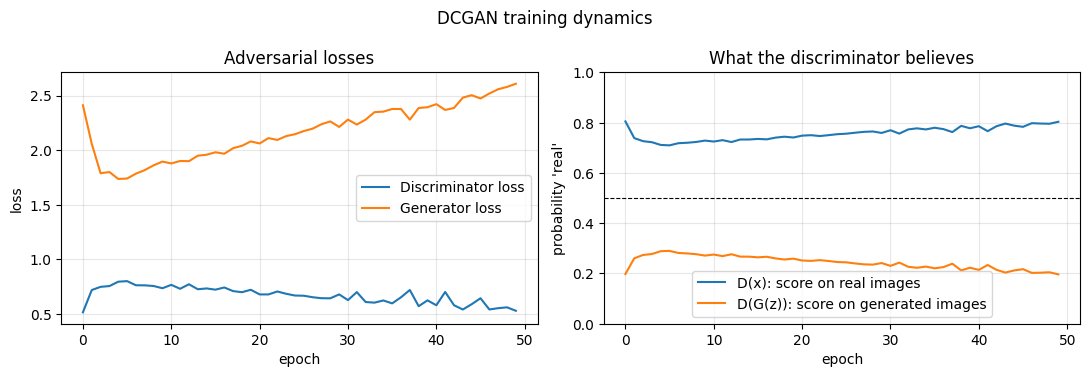

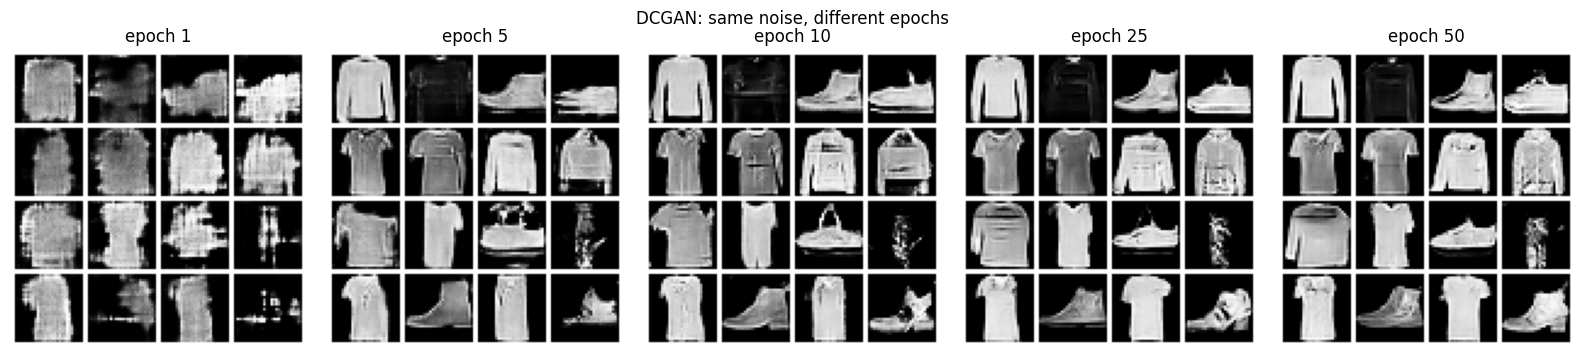

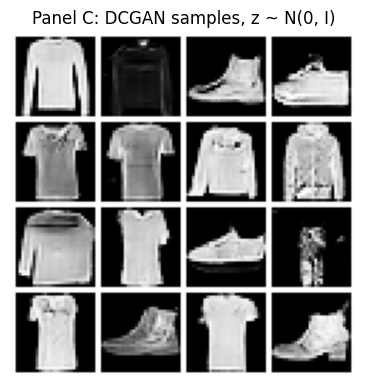


Pairwise diversity (mean L2): real 11.37 | generated 11.43 (ratio 1.01)
Classes present (>2% of samples): 10/10 | entropy ratio 1.00


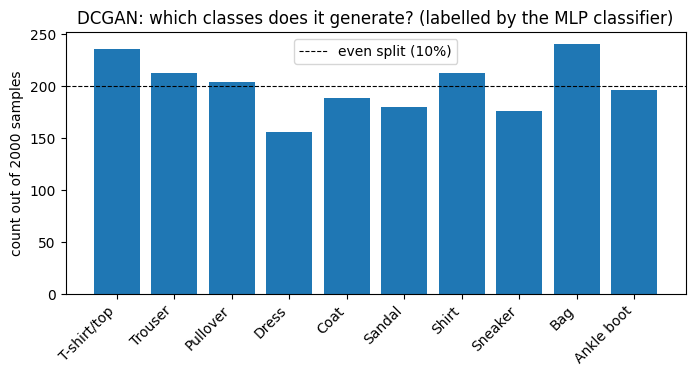


Training roughness over the last 20 epochs:
                            Vanilla GAN     DCGAN
std of G loss                     0.007     0.103
std of D loss                     0.002     0.054
mean |change| in G loss           0.009     0.041
mean G loss                       0.919     2.411
mean D loss                       1.278     0.606
D(x), last epoch                  0.553     0.803
D(G(z)), last epoch               0.449     0.196


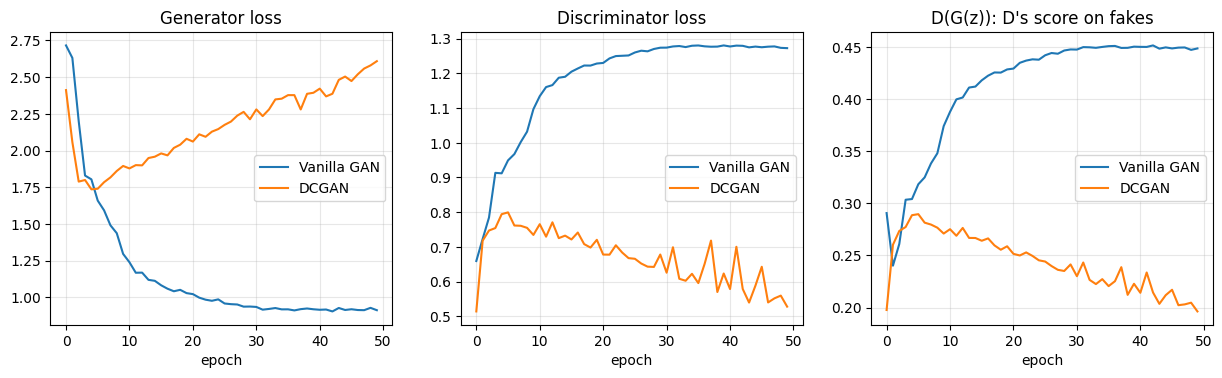


Saved figures/ and results/dcgan_results.json


In [ ]:
LATENT_DIM = 100
EPOCHS = 50
LR = 2e-4
BATCH_SIZE = 128
SNAPSHOT_EPOCHS = (1, 5, 10, 25, 50)
NAME = "dcgan"
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)


def stability_summary(h, last=20):
    """Numbers that describe how rough the training curves are over the last `last` epochs."""
    lg, ld = np.array(h["loss_G"]), np.array(h["loss_D"])
    return {
        "loss_G_mean_last": float(lg[-last:].mean()), "loss_G_std_last": float(lg[-last:].std()),
        "loss_D_mean_last": float(ld[-last:].mean()), "loss_D_std_last": float(ld[-last:].std()),
        "loss_G_mean_abs_change": float(np.abs(np.diff(lg[-last:])).mean()),
        "D_real_last": float(h["D_real"][-1]), "D_fake_last": float(h["D_fake"][-1]),
    }


if __name__ == "__main__":
    set_seed()
    device = get_device()
    train_loader, val_loader, test_loader = get_dataloaders(BATCH_SIZE)

    G = DCGANGenerator(LATENT_DIM)
    D = DCGANDiscriminator()
    print("Generator params:    ", sum(p.numel() for p in G.parameters()))
    print("Discriminator params:", sum(p.numel() for p in D.parameters()))

    history = train_gan(G, D, train_loader, EPOCHS, LR, device, NAME, LATENT_DIM,
                        snapshot_epochs=SNAPSHOT_EPOCHS)
    avg_epoch = sum(history["epoch_time"]) / len(history["epoch_time"])
    print(f"\nAvg train time/epoch: {avg_epoch:.2f}s")

    plot_gan_curves(history, "DCGAN training dynamics", path="figures/dcgan_curves.png")
    plot_snapshots(history["snapshots"], "DCGAN: same noise, different epochs",
                   path="figures/dcgan_snapshots.png")

    # ---------------------------------------------------------- Figure 2, panel C
    samples = G.sample(16, seed=42)
    grid = make_grid(samples.cpu(), nrow=4, padding=2, pad_value=1.0)[0]
    plt.figure(figsize=(4.5, 4.5))
    plt.imshow(grid, cmap="gray", vmin=0, vmax=1)
    plt.axis("off")
    plt.title("Panel C: DCGAN samples, z ~ N(0, I)")
    plt.savefig("figures/fig2_panelC_dcgan_samples.png", dpi=200, bbox_inches="tight")
    plt.show()

    # ---------------------------------------------------------- diagnostics
    results = {"avg_epoch_time": avg_epoch, **stability_summary(history)}
    real_imgs = torch.cat([x for x, _ in test_loader])[:500]
    d_real = pairwise_diversity(real_imgs)
    d_fake = pairwise_diversity(G.sample(500, seed=0).cpu())
    results["diversity_real"], results["diversity_generated"] = d_real, d_fake
    print(f"\nPairwise diversity (mean L2): real {d_real:.2f} | generated {d_fake:.2f} "
          f"(ratio {d_fake / d_real:.2f})")

    clf_path = os.path.join("checkpoints", "mlp_classifier.pt")
    if os.path.exists(clf_path):
        clf = MLPClassifier().to(device)
        clf.load_state_dict(torch.load(clf_path, map_location=device))
        stats = class_histogram(lambda n: G.sample(n), clf, device, n=2000)
        results["class_coverage"] = stats
        print(f"Classes present (>2% of samples): {stats['classes_present']}/10 | "
              f"entropy ratio {stats['entropy_ratio']:.2f}")
        plt.figure(figsize=(8, 3.4))
        plt.bar(CLASS_NAMES, stats["counts"])
        plt.axhline(200, color="k", linestyle="--", linewidth=0.8, label="even split (10%)")
        plt.xticks(rotation=45, ha="right")
        plt.ylabel("count out of 2000 samples")
        plt.title("DCGAN: which classes does it generate? (labelled by the MLP classifier)")
        plt.legend()
        plt.savefig("figures/dcgan_class_coverage.png", dpi=200, bbox_inches="tight")
        plt.show()

    # ---------------------------------------------------------- Vanilla GAN vs DCGAN (Q3)
    van_path = os.path.join("checkpoints", "vanilla_gan_history.json")
    if os.path.exists(van_path):
        with open(van_path) as f:
            van = json.load(f)
        s_van, s_dc = stability_summary(van), stability_summary(history)
        print(f"\nTraining roughness over the last 20 epochs:")
        print(f"{'':<26}{'Vanilla GAN':>13}{'DCGAN':>10}")
        for k, label in [("loss_G_std_last", "std of G loss"),
                         ("loss_D_std_last", "std of D loss"),
                         ("loss_G_mean_abs_change", "mean |change| in G loss"),
                         ("loss_G_mean_last", "mean G loss"),
                         ("loss_D_mean_last", "mean D loss"),
                         ("D_real_last", "D(x), last epoch"),
                         ("D_fake_last", "D(G(z)), last epoch")]:
            print(f"{label:<26}{s_van[k]:>13.3f}{s_dc[k]:>10.3f}")
        results["vanilla_gan_stability"] = s_van

        fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
        for ax, key, ttl in zip(axes, ["loss_G", "loss_D", "D_fake"],
                                ["Generator loss", "Discriminator loss", "D(G(z)): D's score on fakes"]):
            ax.plot(van[key], label="Vanilla GAN")
            ax.plot(history[key], label="DCGAN")
            ax.set_title(ttl)
            ax.set_xlabel("epoch")
            ax.grid(alpha=0.3)
            ax.legend()
        fig.savefig("figures/gan_vs_dcgan_curves.png", dpi=200, bbox_inches="tight")
        plt.show()
    else:
        print("(Skipped comparison: checkpoints/vanilla_gan_history.json not found - run Step 6 first.)")

    with open("results/dcgan_results.json", "w") as f:
        json.dump(results, f, indent=2)
    print("\nSaved figures/ and results/dcgan_results.json")

# Step 8: DDPM

### Model

In [ ]:
class SinusoidalEmbedding(nn.Module):
    """Turns the timestep t (an integer) into a vector of sines/cosines the network can use."""

    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
        args = t.float()[:, None] * freqs[None, :]
        return torch.cat([args.sin(), args.cos()], dim=1)


class ResBlock(nn.Module):
    """Two 3x3 convolutions + a residual connection; the timestep embedding is added in the middle."""

    def __init__(self, in_ch, out_ch, t_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.t_proj = nn.Linear(t_dim, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, t_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.t_proj(F.silu(t_emb))[:, :, None, None]   # "tell the block how noisy the image is"
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class UNet(nn.Module):
    """
    Small U-Net for 28x28 images:   28x28 -> 14x14 -> 7x7 -> 14x14 -> 28x28
    Input : noisy image x_t [B,1,28,28] and timestep t [B]
    Output: predicted noise  [B,1,28,28]   (same shape as the input)
    The skip connections (concatenations) hand fine detail from the early layers
    straight to the later ones.
    """

    def __init__(self, base=64):
        super().__init__()
        t_dim = base * 4
        self.time_mlp = nn.Sequential(
            SinusoidalEmbedding(base), nn.Linear(base, t_dim), nn.SiLU(), nn.Linear(t_dim, t_dim)
        )
        self.in_conv = nn.Conv2d(1, base, 3, padding=1)

        self.down1 = ResBlock(base, base, t_dim)                    # 28x28
        self.pool1 = nn.Conv2d(base, base, 3, stride=2, padding=1)  # -> 14x14
        self.down2 = ResBlock(base, base * 2, t_dim)                # 14x14
        self.pool2 = nn.Conv2d(base * 2, base * 2, 3, stride=2, padding=1)  # -> 7x7

        self.mid1 = ResBlock(base * 2, base * 2, t_dim)             # 7x7
        self.mid2 = ResBlock(base * 2, base * 2, t_dim)

        self.upsample = nn.Upsample(scale_factor=2, mode="nearest")
        self.up_conv2 = nn.Conv2d(base * 2, base * 2, 3, padding=1)
        self.up_block2 = ResBlock(base * 4, base * 2, t_dim)        # 14x14 (after concat with skip)
        self.up_conv1 = nn.Conv2d(base * 2, base * 2, 3, padding=1)
        self.up_block1 = ResBlock(base * 3, base, t_dim)            # 28x28 (after concat with skip)

        self.out = nn.Sequential(nn.GroupNorm(8, base), nn.SiLU(), nn.Conv2d(base, 1, 3, padding=1))

    def forward(self, x, t):
        te = self.time_mlp(t)
        s1 = self.down1(self.in_conv(x), te)       # [B, 64, 28, 28]
        s2 = self.down2(self.pool1(s1), te)        # [B,128, 14, 14]
        h = self.mid2(self.mid1(self.pool2(s2), te), te)           # [B,128, 7, 7]
        h = self.up_conv2(self.upsample(h))                        # [B,128, 14, 14]
        h = self.up_block2(torch.cat([h, s2], dim=1), te)          # [B,128, 14, 14]
        h = self.up_conv1(self.upsample(h))                        # [B,128, 28, 28]
        h = self.up_block1(torch.cat([h, s1], dim=1), te)          # [B, 64, 28, 28]
        return self.out(h)

### Diffusion

In [ ]:
class GaussianDiffusion(nn.Module):
    """
    Forward process : x_t = sqrt(abar_t) * x_0 + sqrt(1 - abar_t) * noise
    Training loss   : MSE between the true noise and the network's prediction
    Reverse process : start from pure noise x_T and denoise step by step down to x_0
    """

    def __init__(self, model, T=1000, beta_start=1e-4, beta_end=0.02):
        super().__init__()
        self.model, self.T = model, T
        betas = torch.linspace(beta_start, beta_end, T)       # how much noise is added at each step
        alphas = 1.0 - betas
        abar = torch.cumprod(alphas, dim=0)                   # fraction of the original signal left at step t
        self.register_buffer("betas", betas)
        self.register_buffer("alphas", alphas)
        self.register_buffer("abar", abar)
        self.register_buffer("sqrt_abar", abar.sqrt())
        self.register_buffer("sqrt_one_minus_abar", (1 - abar).sqrt())

    @staticmethod
    def _at(buf, t):                                          # pick buf[t] and shape it [B,1,1,1]
        return buf[t][:, None, None, None]

    def q_sample(self, x0, t, noise):
        """Forward process: jump straight to step t."""
        return self._at(self.sqrt_abar, t) * x0 + self._at(self.sqrt_one_minus_abar, t) * noise

    def loss(self, x0, generator=None, model=None):
        model = self.model if model is None else model
        t = torch.randint(0, self.T, (x0.size(0),), device=x0.device, generator=generator)
        noise = torch.randn(x0.shape, device=x0.device, generator=generator)
        return F.mse_loss(model(self.q_sample(x0, t, noise), t), noise)

    @torch.no_grad()
    def sample(self, n, seed=None, model=None, snapshot_ts=(), return_snapshots=False):
        """
        Generate n images with T denoising steps (T network evaluations!).
        snapshot_ts: timesteps at which to record the partly-denoised image x_t.
        """
        model = self.model if model is None else model
        model.eval()
        dev = self.betas.device
        g = torch.Generator(device=dev)
        if seed is not None:
            g.manual_seed(seed)
        x = torch.randn(n, 1, 28, 28, generator=g, device=dev)       # x_T: pure noise
        snaps = {}
        for t in range(self.T - 1, -1, -1):
            if t in snapshot_ts:
                snaps[t] = ((x.clamp(-1, 1) + 1) / 2).cpu()
            tt = torch.full((n,), t, device=dev, dtype=torch.long)
            eps = model(x, tt)                                        # predicted noise
            mean = (x - self.betas[t] / self.sqrt_one_minus_abar[t] * eps) / self.alphas[t].sqrt()
            if t > 0:
                x = mean + self.betas[t].sqrt() * torch.randn(x.shape, generator=g, device=dev)
            else:
                x = mean
        out = (x.clamp(-1, 1) + 1) / 2                                # back to [0, 1]
        if return_snapshots:
            snaps[-1] = out.cpu()                                     # -1 stands for the final x_0
            return out, snaps
        return out

### Train

In [ ]:
@torch.no_grad()
def _ema_update(ema, model, decay):
    for pe, p in zip(ema.parameters(), model.parameters()):
        pe.mul_(decay).add_(p.detach(), alpha=1 - decay)


@torch.no_grad()
def evaluate_noise_loss(diffusion, loader, device, model=None, seed=0):
    """Average noise-prediction MSE over a loader (random t, fixed seed so it is repeatable)."""
    model = diffusion.model if model is None else model
    model.eval()
    g = torch.Generator(device=device).manual_seed(seed)
    total, count = 0.0, 0
    for x, _ in loader:
        x = x.to(device) * 2 - 1
        total += diffusion.loss(x, generator=g, model=model).item() * x.size(0)
        count += x.size(0)
    return total / count


def train_ddpm(diffusion, train_loader, val_loader, epochs, lr, device, name,
               ema_decay=0.999, ckpt_dir="checkpoints"):
    """
    Trains the U-Net to predict noise. Also keeps an EMA (exponential moving average)
    copy of the weights, which gives noticeably cleaner samples than the raw weights.
    Returns (history, ema_model).
    """
    os.makedirs(ckpt_dir, exist_ok=True)
    diffusion.to(device)
    model = diffusion.model
    ema = copy.deepcopy(model).eval()
    for p in ema.parameters():
        p.requires_grad = False

    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "epoch_time": []}

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        total, count = 0.0, 0
        for x, _ in train_loader:                       # labels are not used
            x = x.to(device) * 2 - 1                    # [0,1] -> [-1,1]
            loss = diffusion.loss(x)                    # random t, random noise, predict the noise
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # avoid rare huge updates
            opt.step()
            _ema_update(ema, model, ema_decay)
            total += loss.item() * x.size(0)
            count += x.size(0)
        if device.type == "cuda":
            torch.cuda.synchronize()
        epoch_time = time.time() - t0

        val_loss = evaluate_noise_loss(diffusion, val_loader, device)
        history["train_loss"].append(total / count)
        history["val_loss"].append(val_loss)
        history["epoch_time"].append(epoch_time)
        print(f"[{name}] epoch {epoch:3d}/{epochs} | train {total / count:.4f} | "
              f"val {val_loss:.4f} | {epoch_time:.1f}s")

    torch.save(model.state_dict(), os.path.join(ckpt_dir, f"{name}.pt"))
    torch.save(ema.state_dict(), os.path.join(ckpt_dir, f"{name}_ema.pt"))
    with open(os.path.join(ckpt_dir, f"{name}_history.json"), "w") as f:
        json.dump(history, f)
    return history, ema

### Run DDPM Model

U-Net parameters: 2260289
Signal left at the last step (abar_T): 0.000040  (should be ~0 = pure noise)


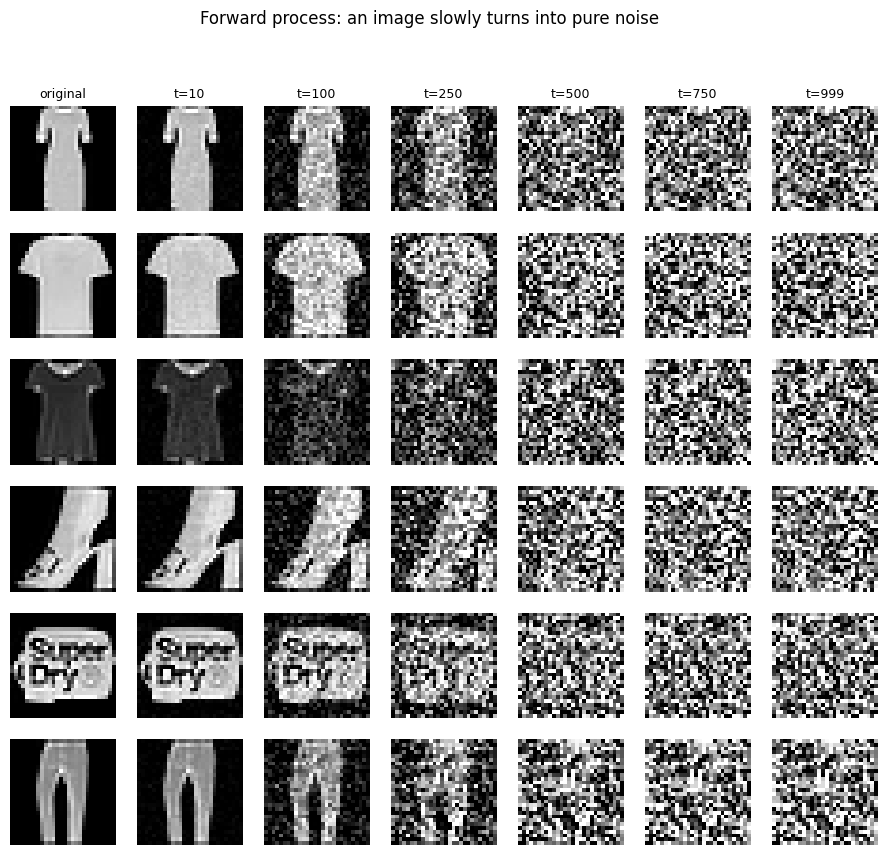

[ddpm] epoch   1/50 | train 0.0787 | val 0.0501 | 58.7s
[ddpm] epoch   2/50 | train 0.0500 | val 0.0447 | 57.4s
[ddpm] epoch   3/50 | train 0.0454 | val 0.0422 | 57.5s
[ddpm] epoch   4/50 | train 0.0435 | val 0.0410 | 57.9s
[ddpm] epoch   5/50 | train 0.0424 | val 0.0405 | 57.4s
[ddpm] epoch   6/50 | train 0.0417 | val 0.0403 | 57.6s
[ddpm] epoch   7/50 | train 0.0405 | val 0.0389 | 58.0s
[ddpm] epoch   8/50 | train 0.0405 | val 0.0387 | 57.9s
[ddpm] epoch   9/50 | train 0.0397 | val 0.0382 | 57.5s
[ddpm] epoch  10/50 | train 0.0403 | val 0.0375 | 57.6s
[ddpm] epoch  11/50 | train 0.0389 | val 0.0372 | 57.8s
[ddpm] epoch  12/50 | train 0.0389 | val 0.0374 | 57.9s
[ddpm] epoch  13/50 | train 0.0389 | val 0.0368 | 58.1s
[ddpm] epoch  14/50 | train 0.0384 | val 0.0369 | 58.0s
[ddpm] epoch  15/50 | train 0.0381 | val 0.0365 | 58.0s
[ddpm] epoch  16/50 | train 0.0380 | val 0.0364 | 58.0s
[ddpm] epoch  17/50 | train 0.0379 | val 0.0363 | 57.9s
[ddpm] epoch  18/50 | train 0.0380 | val 0.0363 

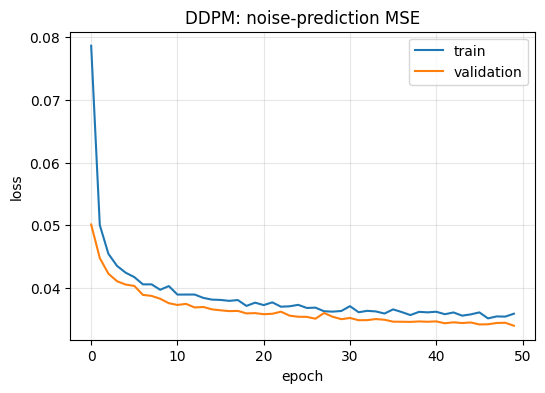

Test noise-prediction loss (EMA weights): 0.0337
Generated 16 samples in 5.8s


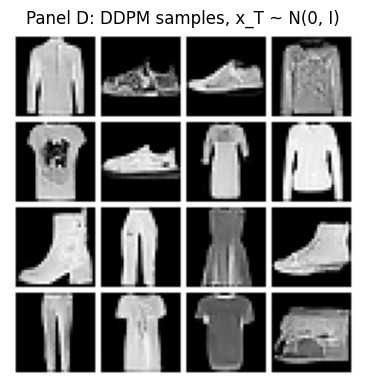

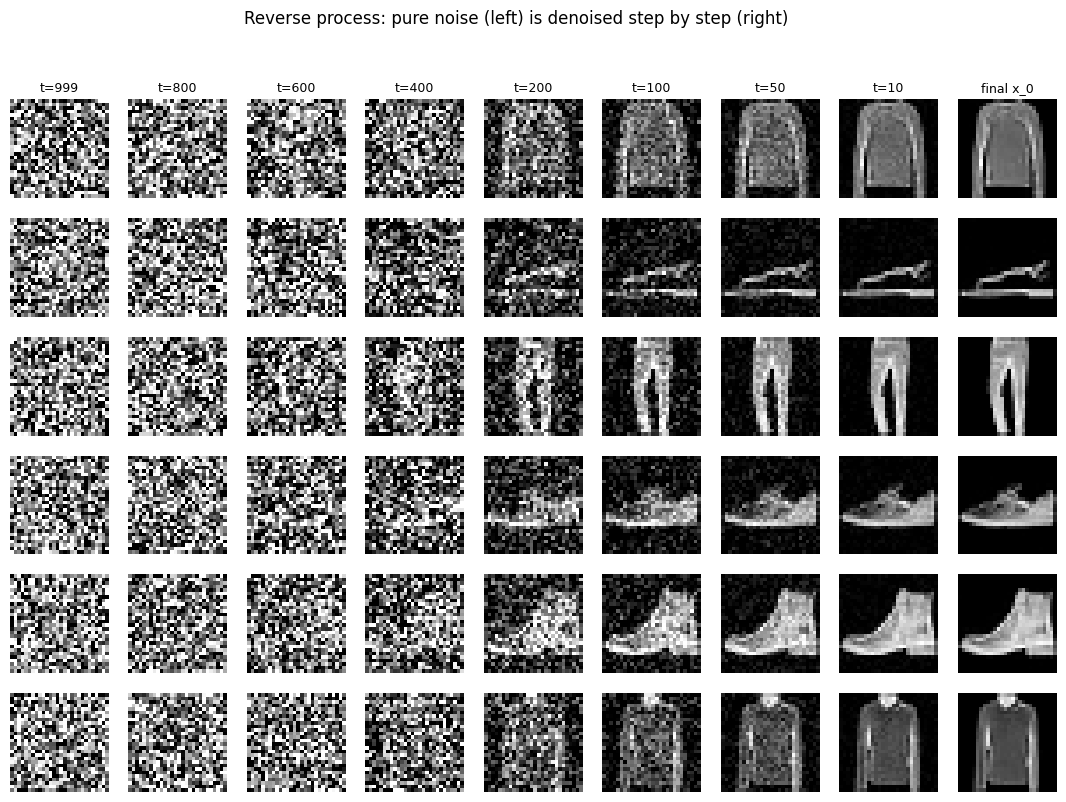


Sampling latency for one batch of 64 images: 22849 ms (1000 network evaluations)
Saved figures/ and results/ddpm_results.json


In [ ]:
T = 1000                 # number of diffusion steps
EPOCHS = 50              # lower this (e.g. 20) for a quicker first try
LR = 2e-4
BATCH_SIZE = 128
NAME = "ddpm"
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)


def sync(device):
    if device.type == "cuda":
        torch.cuda.synchronize()


if __name__ == "__main__":
    set_seed()
    device = get_device()
    train_loader, val_loader, test_loader = get_dataloaders(BATCH_SIZE)

    unet = UNet(base=64)
    diffusion = GaussianDiffusion(unet, T=T).to(device)
    n_params = sum(p.numel() for p in unet.parameters())
    print("U-Net parameters:", n_params)
    print(f"Signal left at the last step (abar_T): {diffusion.abar[-1].item():.6f}  (should be ~0 = pure noise)")

    # ---------------------------------------------------------- picture of the FORWARD process
    x_real, _ = next(iter(test_loader))
    x_real = x_real[:6].to(device)
    ts = [10, 100, 250, 500, 750, 999]
    g = torch.Generator(device=device).manual_seed(0)
    noise = torch.randn(x_real.shape, generator=g, device=device)
    fig, axes = plt.subplots(6, len(ts) + 1, figsize=(1.6 * (len(ts) + 1), 1.6 * 6))
    for r in range(6):
        axes[r, 0].imshow(x_real[r].squeeze().cpu(), cmap="gray", vmin=0, vmax=1)
        for c, t in enumerate(ts, start=1):
            xt = diffusion.q_sample(x_real[r:r + 1] * 2 - 1, torch.tensor([t], device=device), noise[r:r + 1])
            axes[r, c].imshow(((xt.clamp(-1, 1) + 1) / 2).squeeze().cpu(), cmap="gray", vmin=0, vmax=1)
            if r == 0:
                axes[r, c].set_title(f"t={t}", fontsize=9)
        if r == 0:
            axes[r, 0].set_title("original", fontsize=9)
    for ax in axes.flatten():
        ax.axis("off")
    fig.suptitle("Forward process: an image slowly turns into pure noise")
    fig.savefig("figures/ddpm_forward_process.png", dpi=200, bbox_inches="tight")
    plt.show()

    # ---------------------------------------------------------- train
    history, ema = train_ddpm(diffusion, train_loader, val_loader, EPOCHS, LR, device, NAME)
    avg_epoch = sum(history["epoch_time"]) / len(history["epoch_time"])
    print(f"\nAvg train time/epoch: {avg_epoch:.2f}s")
    plot_loss_curves(history, "DDPM: noise-prediction MSE")
    test_noise_loss = evaluate_noise_loss(diffusion, test_loader, device, model=ema)
    print(f"Test noise-prediction loss (EMA weights): {test_noise_loss:.4f}")

    # ---------------------------------------------------------- Figure 2, panel D
    t0 = time.time()
    samples = diffusion.sample(16, seed=42, model=ema)
    print(f"Generated 16 samples in {time.time() - t0:.1f}s")
    grid = make_grid(samples.cpu(), nrow=4, padding=2, pad_value=1.0)[0]
    plt.figure(figsize=(4.5, 4.5))
    plt.imshow(grid, cmap="gray", vmin=0, vmax=1)
    plt.axis("off")
    plt.title("Panel D: DDPM samples, x_T ~ N(0, I)")
    plt.savefig("figures/fig2_panelD_ddpm_samples.png", dpi=200, bbox_inches="tight")
    plt.show()

    # ---------------------------------------------------------- reverse trajectory (Figure 5)
    snap_ts = (999, 800, 600, 400, 200, 100, 50, 10)
    _, snaps = diffusion.sample(6, seed=1, model=ema, snapshot_ts=snap_ts, return_snapshots=True)
    cols = list(snap_ts) + [-1]
    fig, axes = plt.subplots(6, len(cols), figsize=(1.5 * len(cols), 1.5 * 6))
    for c, t in enumerate(cols):
        for r in range(6):
            axes[r, c].imshow(snaps[t][r].squeeze(), cmap="gray", vmin=0, vmax=1)
            axes[r, c].axis("off")
        axes[0, c].set_title("final x_0" if t == -1 else f"t={t}", fontsize=9)
    fig.suptitle("Reverse process: pure noise (left) is denoised step by step (right)")
    fig.savefig("figures/ddpm_reverse_trajectory.png", dpi=200, bbox_inches="tight")
    plt.show()

    # ---------------------------------------------------------- inference latency per batch of 64
    diffusion.sample(8, seed=0, model=ema)                 # warm-up run (not timed)
    sync(device)
    t0 = time.perf_counter()
    diffusion.sample(64, seed=0, model=ema)
    sync(device)
    latency_ms = (time.perf_counter() - t0) * 1000
    print(f"\nSampling latency for one batch of 64 images: {latency_ms:.0f} ms "
          f"({T} network evaluations)")

    results = {"unet_params": n_params, "T": T, "avg_epoch_time": avg_epoch,
               "test_noise_loss": test_noise_loss, "latency_ms_batch64": latency_ms,
               "final_train_loss": history["train_loss"][-1], "final_val_loss": history["val_loss"][-1]}
    with open("results/ddpm_results.json", "w") as f:
        json.dump(results, f, indent=2)
    print("Saved figures/ and results/ddpm_results.json")

# Evaluation

In [ ]:
N_FID = 5000            # generated images per model for FID (lower, e.g. 1000, for a quick test)
BATCH_FOR_FID = 500
os.makedirs("results", exist_ok=True)


# ------------------------------------------------------------------ helpers
def sync(device):
    if device.type == "cuda":
        torch.cuda.synchronize()


def median_ms(fn, device, warmup, reps):
    """Median wall-clock time of fn() in milliseconds, with GPU synchronization."""
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(reps):
        sync(device)
        t0 = time.perf_counter()
        fn()
        sync(device)
        times.append((time.perf_counter() - t0) * 1000)
    return statistics.median(times)


def mean_epoch_time(name):
    with open(os.path.join("checkpoints", f"{name}_history.json")) as f:
        h = json.load(f)["epoch_time"]
    return sum(h) / len(h)


def load(model, name, device):
    model.load_state_dict(torch.load(os.path.join("checkpoints", f"{name}.pt"), map_location=device))
    return model.to(device).eval()


def add_fake_images(fid, sample_fn, device, n, batch):
    done, i = 0, 0
    while done < n:
        m = min(batch, n - done)
        imgs = sample_fn(m, 1000 + i).to(device).float().clamp(0, 1)   # fixed seeds -> reproducible
        fid.update(imgs.repeat(1, 3, 1, 1), real=False)                # Inception expects 3 channels
        done += m
        i += 1


if __name__ == "__main__":
    set_seed()
    device = get_device()
    train_loader, val_loader, test_loader = get_dataloaders(128)

    # ------------------------------------------------------------ load all models
    vanilla_ae = load(VanillaAE(64), "vanilla_ae", device)
    sparse_ae = load(SparseAE(64), "sparse_ae", device)
    vae = load(VAE(64), "vae", device)
    gan_g = load(VanillaGenerator(100), "vanilla_gan_G", device)
    dcgan_g = load(DCGANGenerator(100), "dcgan_G", device)
    unet = load(UNet(64), "ddpm_ema", device)                 # EMA weights, as used for sampling
    diffusion = GaussianDiffusion(unet, T=1000).to(device)

    # ------------------------------------------------------------ 1) reconstruction metrics
    print("Reconstruction metrics on the test set...")
    recon = {"Vanilla AE": evaluate_recon(vanilla_ae, test_loader, device),
             "Sparse AE": evaluate_recon(sparse_ae, test_loader, device),
             "VAE": evaluate_recon(vae, test_loader, device)}
    for k, v in recon.items():
        print(f"  {k:<11} MSE {v['mse']:.5f} | PSNR {v['psnr']:.2f} | SSIM {v['ssim']:.4f}")

    # ------------------------------------------------------------ 2) latency per batch of 64
    print("\nMeasuring latency (batch of 64)...")
    x64 = next(iter(test_loader))[0][:64].to(device)

    @torch.no_grad()
    def ae_forward(m):
        return lambda: m(x64)

    latency = {
        "Vanilla AE": median_ms(ae_forward(vanilla_ae), device, 10, 50),     # reconstruct 64 images
        "Sparse AE": median_ms(ae_forward(sparse_ae), device, 10, 50),
        "VAE": median_ms(lambda: vae.sample(64, seed=0), device, 10, 50),    # generate 64 images
        "Vanilla GAN": median_ms(lambda: gan_g.sample(64, seed=0), device, 10, 50),
        "DCGAN": median_ms(lambda: dcgan_g.sample(64, seed=0), device, 10, 50),
        "DDPM": median_ms(lambda: diffusion.sample(64, seed=0), device, 1, 3),  # 1000 network passes
    }
    for k, v in latency.items():
        print(f"  {k:<12} {v:10.2f} ms")

    # ------------------------------------------------------------ 3) FID
    print(f"\nFID ({N_FID} generated images per model vs the 7000 test images)...")
    fid = FrechetInceptionDistance(feature=2048, normalize=True, reset_real_features=False).to(device)
    for x, _ in test_loader:                                  # real statistics, computed once
        fid.update(x.to(device).repeat(1, 3, 1, 1), real=True)

    # reference floor: real TRAINING images vs the real test images
    fid.reset()                                               # keeps the real statistics
    for x, _ in DataLoader(Subset(train_loader.dataset, range(N_FID)), batch_size=500):
        fid.update(x.to(device).repeat(1, 3, 1, 1), real=False)
    fid_floor = fid.compute().item()
    print(f"  {'real train vs test (floor)':<28} {fid_floor:8.2f}")

    generators = [
        ("VAE", lambda m, s: vae.sample(m, seed=s), BATCH_FOR_FID),
        ("Vanilla GAN", lambda m, s: gan_g.sample(m, seed=s), BATCH_FOR_FID),
        ("DCGAN", lambda m, s: dcgan_g.sample(m, seed=s), BATCH_FOR_FID),
        ("DDPM", lambda m, s: diffusion.sample(m, seed=s), 500),          # slowest: 1000 steps/batch
    ]
    fid_scores = {}
    for name, fn, batch in generators:
        t0 = time.time()
        fid.reset()
        add_fake_images(fid, fn, device, N_FID, batch)
        fid_scores[name] = fid.compute().item()
        print(f"  {name:<28} {fid_scores[name]:8.2f}   ({time.time() - t0:.0f}s)")

    # ------------------------------------------------------------ 4) compile the table
    rows = []
    spec = [("Vanilla AE", "vanilla_ae", "64"), ("Sparse AE", "sparse_ae", "64 (bottleneck) / 256 (sparse)"),
            ("VAE", "vae", "64"), ("Vanilla GAN", "vanilla_gan", "100 (noise)"),
            ("DCGAN", "dcgan", "100 (noise)"), ("DDPM", "ddpm", "28x28 (image)")]
    for label, ckpt_name, latent in spec:
        r = recon.get(label)
        rows.append({
            "Model": label, "Latent dim": latent,
            "Train time/epoch (s)": f"{mean_epoch_time(ckpt_name):.2f}",
            "Latency (ms/batch 64)": f"{latency[label]:.2f}",
            "Test MSE": f"{r['mse']:.5f}" if r else "N/A",
            "Test PSNR (dB)": f"{r['psnr']:.2f}" if r else "N/A",
            "Test SSIM": f"{r['ssim']:.4f}" if r else "N/A",
            "FID": f"{fid_scores[label]:.2f}" if label in fid_scores else "N/A",
        })

    with open("results/metrics_table.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        w.writeheader()
        w.writerows(rows)
    header = list(rows[0].keys())
    md = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    md += ["| " + " | ".join(r[h] for h in header) + " |" for r in rows]
    with open("results/metrics_table.md", "w") as f:
        f.write("\n".join(md) + f"\n\nFID reference floor (real train vs real test, n={N_FID}): {fid_floor:.2f}\n")
    with open("results/evaluation_results.json", "w") as f:
        json.dump({"recon": recon, "latency_ms": latency, "fid": fid_scores, "fid_floor": fid_floor,
                   "n_fid": N_FID}, f, indent=2)

    print("\n" + "\n".join(md))
    print(f"\nFID floor (real train vs real test): {fid_floor:.2f}")
    print(f"DDPM is {latency['DDPM'] / latency['DCGAN']:.0f}x slower than DCGAN per batch of 64.")
    print("Saved results/metrics_table.csv, metrics_table.md, evaluation_results.json")

Reconstruction metrics on the test set...
  Vanilla AE  MSE 0.00651 | PSNR 22.99 | SSIM 0.7889
  Sparse AE   MSE 0.01115 | PSNR 20.49 | SSIM 0.6842
  VAE         MSE 0.01334 | PSNR 19.60 | SSIM 0.6454

Measuring latency (batch of 64)...
  Vanilla AE         0.56 ms
  Sparse AE          0.63 ms
  VAE                0.41 ms
  Vanilla GAN        0.64 ms
  DCGAN              6.65 ms
  DDPM           22045.11 ms

FID (5000 generated images per model vs the 7000 test images)...


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 155MB/s]


  real train vs test (floor)       4.50
  VAE                             87.00   (26s)
  Vanilla GAN                    101.20   (26s)
  DCGAN                           11.73   (27s)
  DDPM                             9.06   (1766s)

| Model | Latent dim | Train time/epoch (s) | Latency (ms/batch 64) | Test MSE | Test PSNR (dB) | Test SSIM | FID |
|---|---|---|---|---|---|---|---|
| Vanilla AE | 64 | 7.37 | 0.56 | 0.00651 | 22.99 | 0.7889 | N/A |
| Sparse AE | 64 (bottleneck) / 256 (sparse) | 7.31 | 0.63 | 0.01115 | 20.49 | 0.6842 | N/A |
| VAE | 64 | 7.65 | 0.41 | 0.01334 | 19.60 | 0.6454 | 87.00 |
| Vanilla GAN | 100 (noise) | 9.56 | 0.64 | N/A | N/A | N/A | 101.20 |
| DCGAN | 100 (noise) | 23.42 | 6.65 | N/A | N/A | N/A | 11.73 |
| DDPM | 28x28 (image) | 57.77 | 22045.11 | N/A | N/A | N/A | 9.06 |

FID floor (real train vs real test): 4.50
DDPM is 3314x slower than DCGAN per batch of 64.
Saved results/metrics_table.csv, metrics_table.md, evaluation_results.json


# Figure 4 - Interpolation

Vanilla GAN: endpoint classifier confidence T-shirt/top 1.00, Sneaker 1.00
DCGAN: endpoint classifier confidence T-shirt/top 1.00, Sneaker 1.00


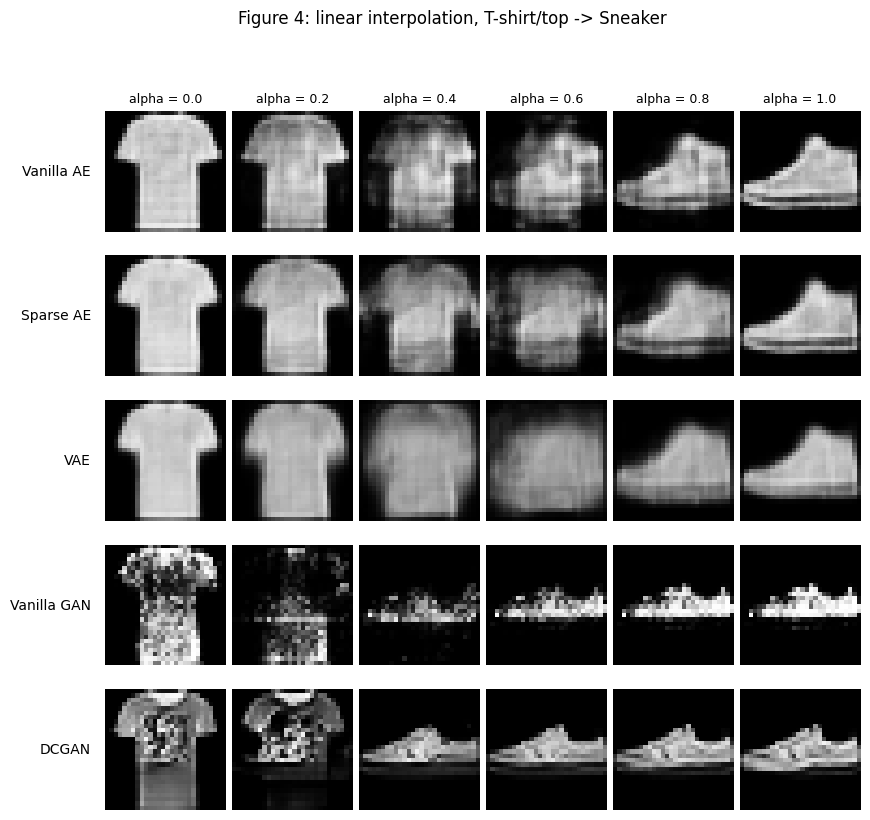

Saved figures/fig4_interpolation.png


In [ ]:
CLASS_A, CLASS_B = 0, 7                 # T-shirt/top -> Sneaker (change to try other pairs)
ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
os.makedirs("figures", exist_ok=True)


def load(model, name, device):
    model.load_state_dict(torch.load(os.path.join("checkpoints", f"{name}.pt"), map_location=device))
    return model.to(device).eval()


def first_test_image_of_class(loader, target, device):
    for x, y in loader:
        idx = (y == target).nonzero()
        if len(idx) > 0:
            return x[idx[0, 0]].unsqueeze(0).to(device)
    raise ValueError(f"class {target} not found")


@torch.no_grad()
def interpolate(decode, z_a, z_b):
    """Decode the 6 points on the straight line between z_a and z_b (both shape [D])."""
    z = torch.stack([(1 - a) * z_a + a * z_b for a in ALPHAS])
    return decode(z).cpu()


@torch.no_grad()
def find_noise_for_class(G, clf, target, device, latent_dim, n=2000, seed=0):
    """Among n random noise vectors, return the one whose image the classifier is most sure is `target`."""
    g = torch.Generator(device=device).manual_seed(seed)
    z = torch.randn(n, latent_dim, generator=g, device=device)
    probs = F.softmax(clf((G(z) + 1) / 2), dim=1)[:, target]
    best = probs.argmax()
    return z[best], probs[best].item()


if __name__ == "__main__":
    set_seed()
    device = get_device()
    _, _, test_loader = get_dataloaders(128)

    vanilla = load(VanillaAE(64), "vanilla_ae", device)
    sparse = load(SparseAE(64), "sparse_ae", device)
    vae = load(VAE(64), "vae", device)
    gan_g = load(VanillaGenerator(100), "vanilla_gan_G", device)
    dcgan_g = load(DCGANGenerator(100), "dcgan_G", device)
    clf = load(MLPClassifier(), "mlp_classifier", device)

    x_a = first_test_image_of_class(test_loader, CLASS_A, device)
    x_b = first_test_image_of_class(test_loader, CLASS_B, device)

    rows = []
    with torch.no_grad():
        # --- models with an encoder: interpolate between the codes of two real images
        for label, m in [("Vanilla AE", vanilla), ("Sparse AE", sparse)]:
            rows.append((label, interpolate(m.decode, m.encode(x_a)[0], m.encode(x_b)[0])))
        rows.append(("VAE", interpolate(vae.decode, vae.encode(x_a)[0][0], vae.encode(x_b)[0][0])))  # use mu

        # --- GANs: interpolate between two noise vectors that generate the two chosen classes
        for label, G in [("Vanilla GAN", gan_g), ("DCGAN", dcgan_g)]:
            z_a, p_a = find_noise_for_class(G, clf, CLASS_A, device, 100)
            z_b, p_b = find_noise_for_class(G, clf, CLASS_B, device, 100)
            print(f"{label}: endpoint classifier confidence "
                  f"{CLASS_NAMES[CLASS_A]} {p_a:.2f}, {CLASS_NAMES[CLASS_B]} {p_b:.2f}")
            rows.append((label, interpolate(lambda z: (G(z) + 1) / 2, z_a, z_b)))

    fig, axes = plt.subplots(len(rows), len(ALPHAS), figsize=(1.7 * len(ALPHAS), 1.7 * len(rows) + 0.8))
    for r, (label, imgs) in enumerate(rows):
        for c in range(len(ALPHAS)):
            axes[r, c].imshow(imgs[c].squeeze(), cmap="gray", vmin=0, vmax=1)
            axes[r, c].axis("off")
            if r == 0:
                axes[r, c].set_title(f"alpha = {ALPHAS[c]:.1f}", fontsize=9)
        axes[r, 0].text(-0.12, 0.5, label, transform=axes[r, 0].transAxes,
                        ha="right", va="center", fontsize=10)
    fig.suptitle(f"Figure 4: linear interpolation, {CLASS_NAMES[CLASS_A]} -> {CLASS_NAMES[CLASS_B]}")
    plt.subplots_adjust(left=0.16, wspace=0.05, hspace=0.05)
    fig.savefig("figures/fig4_interpolation.png", dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved figures/fig4_interpolation.png")

# Figure 5 - Training curves for all six models

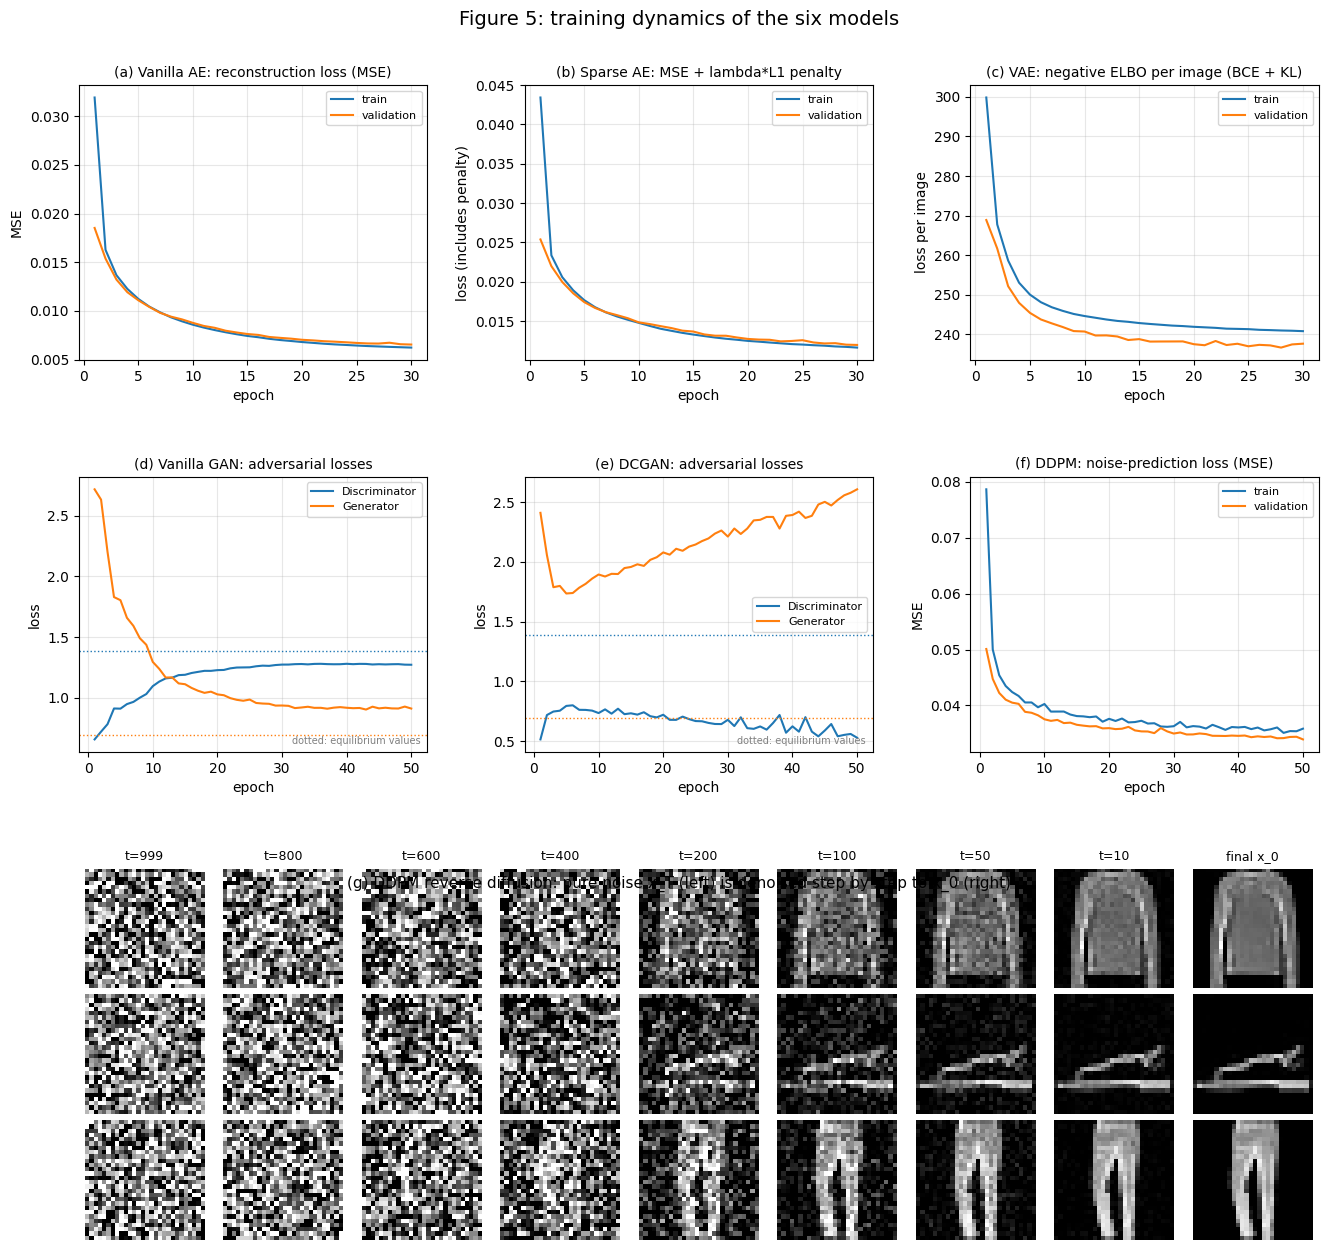

Saved figures/fig5_training_curves_and_ddpm.png


In [ ]:
os.makedirs("figures", exist_ok=True)


def history(name):
    with open(os.path.join("checkpoints", f"{name}_history.json")) as f:
        return json.load(f)


def draw(ax, h, series, title, ylabel):
    for key, label in series:
        y = h[key]
        ax.plot(range(1, len(y) + 1), y, label=label)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)


if __name__ == "__main__":
    device = get_device()
    fig = plt.figure(figsize=(16, 15))
    gs = fig.add_gridspec(3, 3, height_ratios=[1, 1, 1.35], hspace=0.38, wspace=0.28)

    # (a) Vanilla AE
    ax = fig.add_subplot(gs[0, 0])
    draw(ax, history("vanilla_ae"), [("train_loss", "train"), ("val_loss", "validation")],
         "(a) Vanilla AE: reconstruction loss (MSE)", "MSE")

    # (b) Sparse AE  (its loss includes the L1 penalty)
    ax = fig.add_subplot(gs[0, 1])
    draw(ax, history("sparse_ae"), [("train_loss", "train"), ("val_loss", "validation")],
         "(b) Sparse AE: MSE + lambda*L1 penalty", "loss (includes penalty)")

    # (c) VAE  (negative ELBO per image)
    ax = fig.add_subplot(gs[0, 2])
    draw(ax, history("vae"), [("train_loss", "train"), ("val_loss", "validation")],
         "(c) VAE: negative ELBO per image (BCE + KL)", "loss per image")

    # (d), (e) the two GANs: Discriminator and Generator loss + theoretical equilibrium
    for col, (name, title) in enumerate([("vanilla_gan", "(d) Vanilla GAN: adversarial losses"),
                                         ("dcgan", "(e) DCGAN: adversarial losses")]):
        ax = fig.add_subplot(gs[1, col])
        draw(ax, history(name), [("loss_D", "Discriminator"), ("loss_G", "Generator")],
             title, "loss")
        ax.axhline(2 * 0.6931, color="tab:blue", linestyle=":", linewidth=1)    # D loss if D = 0.5 everywhere
        ax.axhline(0.6931, color="tab:orange", linestyle=":", linewidth=1)      # G loss if D = 0.5 everywhere
        ax.text(0.98, 0.02, "dotted: equilibrium values", transform=ax.transAxes,
                ha="right", va="bottom", fontsize=7, color="gray")

    # (f) DDPM noise-prediction loss
    ax = fig.add_subplot(gs[1, 2])
    draw(ax, history("ddpm"), [("train_loss", "train"), ("val_loss", "validation")],
         "(f) DDPM: noise-prediction loss (MSE)", "MSE")

    # (g) DDPM reverse process: x_T -> x_0 (three different images)
    unet = UNet(64).to(device)
    unet.load_state_dict(torch.load(os.path.join("checkpoints", "ddpm_ema.pt"), map_location=device))
    unet.eval()
    diffusion = GaussianDiffusion(unet, T=1000).to(device)
    snap_ts = (999, 800, 600, 400, 200, 100, 50, 10)
    _, snaps = diffusion.sample(3, seed=1, snapshot_ts=snap_ts, return_snapshots=True)
    cols = list(snap_ts) + [-1]

    sub = gs[2, :].subgridspec(3, len(cols), wspace=0.05, hspace=0.05)
    for r in range(3):
        for c, t in enumerate(cols):
            ax = fig.add_subplot(sub[r, c])
            ax.imshow(snaps[t][r].squeeze(), cmap="gray", vmin=0, vmax=1)
            ax.axis("off")
            if r == 0:
                ax.set_title("final x_0" if t == -1 else f"t={t}", fontsize=9)
    fig.text(0.5, 0.345, "(g) DDPM reverse diffusion: pure noise x_T (left) is denoised step by step to x_0 (right)",
             ha="center", fontsize=11)

    fig.suptitle("Figure 5: training dynamics of the six models", fontsize=14, y=0.93)
    fig.savefig("figures/fig5_training_curves_and_ddpm.png", dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved figures/fig5_training_curves_and_ddpm.png")

# Figure 2 and 3

In [ ]:
FIG = "figures"
DPI = 250


def read(name):
    path = os.path.join(FIG, name)
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} not found - run the step that creates it first.")
    return plt.imread(path)


def make_fig2():
    names = ["fig2_panelA_vae_samples.png", "fig2_panelB_vanilla_gan_samples.png",
             "fig2_panelC_dcgan_samples.png", "fig2_panelD_ddpm_samples.png"]
    imgs = [read(n) for n in names]
    fig, axes = plt.subplots(2, 2, figsize=(10, 10.6))
    for ax, img in zip(axes.flatten(), imgs):
        ax.imshow(img, interpolation="lanczos")
        ax.axis("off")
    fig.suptitle("Figure 2: random generative sampling (16 samples per model, fixed seed 42)", fontsize=13)
    plt.subplots_adjust(wspace=0.02, hspace=0.02, top=0.93, left=0.02, right=0.98, bottom=0.02)
    out = os.path.join(FIG, "fig2_random_sampling_grid.png")
    fig.savefig(out, dpi=DPI, bbox_inches="tight")
    plt.close(fig)
    print("Saved", out)


def make_fig3():
    top, bottom = read("fig3_panels_1_to_3.png"), read("fig3_panel_4_sampling.png")
    width_in = 15.0
    row1 = width_in * top.shape[0] / top.shape[1]            # keep each image's aspect ratio
    w2 = width_in * 0.62
    row2 = w2 * bottom.shape[0] / bottom.shape[1]
    gap = 0.2
    total = row1 + row2 + gap
    fig = plt.figure(figsize=(width_in, total))
    ax1 = fig.add_axes([0, (row2 + gap) / total, 1, row1 / total])
    ax2 = fig.add_axes([(1 - 0.62) / 2, 0, 0.62, row2 / total])
    ax1.imshow(top, interpolation="lanczos")
    ax2.imshow(bottom, interpolation="lanczos")
    ax1.axis("off")
    ax2.axis("off")
    out = os.path.join(FIG, "fig3_mlp_classifier_limits.png")
    fig.savefig(out, dpi=DPI)
    plt.close(fig)
    print("Saved", out)


if __name__ == "__main__":
    make_fig2()
    make_fig3()

    final = {
        "Figure 1": "fig1_reconstruction_grid.png",
        "Figure 2": "fig2_random_sampling_grid.png",
        "Figure 3": "fig3_mlp_classifier_limits.png",
        "Figure 4": "fig4_interpolation.png",
        "Figure 5": "fig5_training_curves_and_ddpm.png",
    }
    print("\nFinal report figures:")
    for label, name in final.items():
        ok = os.path.exists(os.path.join(FIG, name))
        print(f"  {label}: {name}  {'OK' if ok else 'MISSING'}")

Saved figures/fig2_random_sampling_grid.png
Saved figures/fig3_mlp_classifier_limits.png

Final report figures:
  Figure 1: fig1_reconstruction_grid.png  OK
  Figure 2: fig2_random_sampling_grid.png  OK
  Figure 3: fig3_mlp_classifier_limits.png  OK
  Figure 4: fig4_interpolation.png  OK
  Figure 5: fig5_training_curves_and_ddpm.png  OK
